# Part A — Data audit & cleaning, before/after EDA, driver-race grain, Data-Engineering Question 1

In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


def note(text):
    display(Markdown(text))


TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings", "drivers", "driver_standings",
    "lap_times", "pit_stops", "qualifying", "races", "results", "seasons", "sprint_results", "status",
]


def find_dataset_dir():
    candidates = [Path(p) for p in [os.environ.get("F1_DATASET_DIR"), "archive", "."] if p]
    for root in [Path("/kaggle/input"), Path.cwd()]:
        if root.exists():
            candidates += [p.parent for p in root.rglob("circuits.csv")]
    for candidate in candidates:
        if all((candidate / f"{t}.csv").exists() for t in TABLES):
            return candidate
    raise FileNotFoundError("Could not find the 14 F1 CSVs. Attach the Kaggle dataset or set F1_DATASET_DIR.")


DATA_DIR = find_dataset_dir()
raw_tables = {t: pd.read_csv(DATA_DIR / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
raw_summary = pd.DataFrame(
    [
        {
            "table": t,
            "rows": len(df),
            "columns": df.shape[1],
            "sentinel_cells": int((df == "\\N").sum().sum()),
            "blank_cells": int((df == "").sum().sum()),
        }
        for t, df in raw_tables.items()
    ]
)
print(f"Dataset directory: {DATA_DIR.resolve()}  (raw files are read as strings and never modified)")
display(raw_summary)

Dataset directory: /Users/mohamed.ismail/code/untitled folder/archive  (raw files are read as strings and never modified)


,table,rows,columns,sentinel_cells,blank_cells
0,circuits,77,9,0,0
1,constructors,212,5,0,0
2,constructor_results,12625,5,12608,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,1559,0
5,driver_standings,34863,7,0,0
6,lap_times,589081,6,0,0
7,pit_stops,11371,7,0,0
8,qualifying,10494,9,11600,68
9,races,1125,18,11349,0


In [2]:
NUMERIC_COLUMNS = {
    "circuits": ["circuitId", "lat", "lng", "alt"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId", "raceId", "constructorId", "points"],
    "constructor_standings": ["constructorStandingsId", "raceId", "constructorId", "points", "position", "wins"],
    "drivers": ["driverId", "number"],
    "driver_standings": ["driverStandingsId", "raceId", "driverId", "points", "position", "wins"],
    "lap_times": ["raceId", "driverId", "lap", "position", "milliseconds"],
    "pit_stops": ["raceId", "driverId", "stop", "lap", "milliseconds"],
    "qualifying": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],
    "races": ["raceId", "year", "round", "circuitId"],
    "results": [
        "resultId", "raceId", "driverId", "constructorId", "number", "grid", "position", "positionOrder",
        "points", "laps", "milliseconds", "fastestLap", "rank", "fastestLapSpeed", "statusId",
    ],
    "seasons": ["year"],
    "sprint_results": [
        "resultId", "raceId", "driverId", "constructorId", "number", "grid", "position", "positionOrder",
        "points", "laps", "milliseconds", "fastestLap", "statusId",
    ],
    "status": ["statusId"],
}
DURATION_COLUMNS = {
    "qualifying": {"q1": "q1_sec", "q2": "q2_sec", "q3": "q3_sec"},
    "lap_times": {"milliseconds": "lap_time_sec"},
    "pit_stops": {"milliseconds": "pit_duration_sec"},
    "results": {"milliseconds": "race_time_sec", "fastestLapTime": "fastestLapTime_sec"},
    "sprint_results": {"milliseconds": "race_time_sec", "fastestLapTime": "fastestLapTime_sec"},
}


def parse_duration_to_seconds(value):
    """'1:27.452' -> 87.452, '16:44.718' -> 1004.718, '+5.2' -> 5.2, unparseable -> NaN."""
    if pd.isna(value):
        return np.nan
    try:
        seconds = 0.0
        for part in str(value).strip().lstrip("+").split(":"):
            seconds = seconds * 60 + float(part)
        return seconds
    except ValueError:
        return np.nan


def clean_table(name, raw_df):
    df = raw_df.mask(raw_df.isin(["\\N", ""]))
    log = {"table": name, "sentinel_or_blank_to_missing": int(df.isna().sum().sum()), "coerced_to_missing": 0}
    date_cols = [c for c in df.columns if c in ("date", "dob") or c.endswith("_date")]
    for col in NUMERIC_COLUMNS.get(name, []) + date_cols:
        present = df[col].notna()
        if col in date_cols:
            df[col] = pd.to_datetime(df[col], errors="coerce", format="%Y-%m-%d")
        else:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        log["coerced_to_missing"] += int((present & df[col].isna()).sum())
    for source, target in DURATION_COLUMNS.get(name, {}).items():
        df[target] = df[source] / 1000.0 if source == "milliseconds" else df[source].map(parse_duration_to_seconds)
    log.update(
        numeric_columns=len(NUMERIC_COLUMNS.get(name, [])),
        datetime_columns=len(date_cols),
        duration_seconds_columns=len(DURATION_COLUMNS.get(name, {})),
        missing_cells_after=int(df.isna().sum().sum()),
    )
    return df, log


cleaned = {name: clean_table(name, df) for name, df in raw_tables.items()}
tables = {name: df for name, (df, _) in cleaned.items()}
cleaning_log = pd.DataFrame([log for _, log in cleaned.values()])

CLEANED_DIR = Path(os.environ.get("F1_CLEANED_DIR", "cleaned_f1"))
CLEANED_DIR.mkdir(parents=True, exist_ok=True)
for name, df in tables.items():
    df.to_csv(CLEANED_DIR / f"{name}.csv", index=False)
print(f"Wrote {len(tables)} cleaned copies to {CLEANED_DIR.resolve()}")
display(cleaning_log)

Wrote 14 cleaned copies to /Users/mohamed.ismail/code/untitled folder/cleaned_f1


,table,sentinel_or_blank_to_missing,coerced_to_missing,numeric_columns,datetime_columns,duration_seconds_columns,missing_cells_after
0,circuits,0,0,4,0,0,0
1,constructors,0,0,1,0,0,0
2,constructor_results,12608,0,4,0,0,12608
3,constructor_standings,0,0,6,0,0,0
4,drivers,1559,0,2,1,0,1559
5,driver_standings,0,0,6,0,0,0
6,lap_times,0,0,5,0,1,0
7,pit_stops,0,0,5,0,1,0
8,qualifying,11668,0,6,0,3,23336
9,races,11349,0,4,6,0,11349


In [3]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"], "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"], "qualifying": ["qualifyId"],
    "races": ["raceId"], "results": ["resultId"], "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}
JOIN_KEYS = {
    "results": ["raceId", "driverId"],
    "qualifying": ["raceId", "driverId"],
    "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"],
}
FOREIGN_KEYS = [
    ("races", "circuitId", "circuits", "circuitId"),
    *[(child, "raceId", "races", "raceId") for child in
      ["results", "qualifying", "lap_times", "pit_stops", "driver_standings", "constructor_standings", "constructor_results", "sprint_results"]],
    *[(child, "driverId", "drivers", "driverId") for child in
      ["results", "qualifying", "lap_times", "pit_stops", "driver_standings", "sprint_results"]],
    *[(child, "constructorId", "constructors", "constructorId") for child in
      ["results", "qualifying", "constructor_standings", "constructor_results", "sprint_results"]],
    ("results", "statusId", "status", "statusId"),
    ("sprint_results", "statusId", "status", "statusId"),
]


def key_check(table, keys, kind):
    df = tables[table]
    null_rows = int(df[keys].isna().any(axis=1).sum())
    duplicate_rows = int(df.duplicated(keys, keep=False).sum())
    return {"table": table, "key": ", ".join(keys), "kind": kind, "null_key_rows": null_rows,
            "duplicate_key_rows": duplicate_rows, "passes": null_rows == 0 and duplicate_rows == 0}


def fk_check(child, col, parent, parent_col):
    values = tables[child][col]
    orphan = values.notna() & ~values.isin(tables[parent][parent_col])
    return {"child": f"{child}.{col}", "parent": f"{parent}.{parent_col}", "checked_rows": int(values.notna().sum()),
            "null_rows": int(values.isna().sum()), "orphan_rows": int(orphan.sum()),
            "orphan_examples": values[orphan].drop_duplicates().head(5).tolist(), "passes": int(orphan.sum()) == 0}


key_audit = pd.DataFrame(
    [key_check(t, k, "primary key") for t, k in PRIMARY_KEYS.items()]
    + [key_check(t, k, "join key (raceId-level)") for t, k in JOIN_KEYS.items()]
)
fk_audit = pd.DataFrame([fk_check(*fk) for fk in FOREIGN_KEYS])
assert key_audit.query("kind == 'primary key'")["passes"].all(), "A primary key is null or duplicated"

display(key_audit)
display(fk_audit)
key_audit.to_csv(CLEANED_DIR / "key_audit.csv", index=False)
fk_audit.to_csv(CLEANED_DIR / "foreign_key_audit.csv", index=False)
cleaning_log.to_csv(CLEANED_DIR / "cleaning_log.csv", index=False)

failed_join_keys = key_audit.query("kind != 'primary key' and not passes")
note(
    "**Audit summary and decisions**\n"
    f"- Sentinels: {int(cleaning_log['sentinel_or_blank_to_missing'].sum()):,} literal `\\N` / blank cells became proper missing values; "
    f"{int(cleaning_log['coerced_to_missing'].sum()):,} additional non-sentinel values failed numeric/date parsing and were set to missing.\n"
    "- Semantic types: IDs, positions, points and counts are numeric; `date`, `*_date` and `dob` are datetimes; "
    "qualifying q1/q2/q3, lap times, pit stops, race times and fastest laps also get a `*_sec` duration column.\n"
    f"- Primary keys: all {len(PRIMARY_KEYS)} tables pass (unique and non-null).\n"
    f"- Foreign keys: {int(fk_audit['passes'].sum())}/{len(fk_audit)} relationships have zero orphan rows; "
    f"{int(fk_audit['orphan_rows'].sum())} orphan rows in total. Joins are left joins from results, so an orphan would surface as a missing attribute, never as a dropped or duplicated row.\n"
    f"- Join keys failing uniqueness: {', '.join(failed_join_keys['table'] + ' (' + failed_join_keys['duplicate_key_rows'].astype(str) + ' rows)') or 'none'}. "
    "`results (raceId, driverId)` duplicates are shared drives and are resolved in the driver-race grain step below; every other join key is unique, so joins at this grain cannot fan out."
)

,table,key,kind,null_key_rows,duplicate_key_rows,passes
0,circuits,circuitId,primary key,0,0,True
1,constructors,constructorId,primary key,0,0,True
2,constructor_results,constructorResultsId,primary key,0,0,True
3,constructor_standings,constructorStandingsId,primary key,0,0,True
4,drivers,driverId,primary key,0,0,True
5,driver_standings,driverStandingsId,primary key,0,0,True
6,lap_times,"raceId, driverId, lap",primary key,0,0,True
7,pit_stops,"raceId, driverId, stop",primary key,0,0,True
8,qualifying,qualifyId,primary key,0,0,True
9,races,raceId,primary key,0,0,True


,child,parent,checked_rows,null_rows,orphan_rows,orphan_examples,passes
0,races.circuitId,circuits.circuitId,1125,0,0,[],True
1,results.raceId,races.raceId,26759,0,0,[],True
2,qualifying.raceId,races.raceId,10494,0,0,[],True
3,lap_times.raceId,races.raceId,589081,0,0,[],True
4,pit_stops.raceId,races.raceId,11371,0,0,[],True
5,driver_standings.raceId,races.raceId,34863,0,0,[],True
6,constructor_standings.raceId,races.raceId,13391,0,0,[],True
7,constructor_results.raceId,races.raceId,12625,0,0,[],True
8,sprint_results.raceId,races.raceId,360,0,0,[],True
9,results.driverId,drivers.driverId,26759,0,0,[],True


**Audit summary and decisions**
- Sentinels: 160,144 literal `\N` / blank cells became proper missing values; 0 additional non-sentinel values failed numeric/date parsing and were set to missing.
- Semantic types: IDs, positions, points and counts are numeric; `date`, `*_date` and `dob` are datetimes; qualifying q1/q2/q3, lap times, pit stops, race times and fastest laps also get a `*_sec` duration column.
- Primary keys: all 14 tables pass (unique and non-null).
- Foreign keys: 22/22 relationships have zero orphan rows; 0 orphan rows in total. Joins are left joins from results, so an orphan would surface as a missing attribute, never as a dropped or duplicated row.
- Join keys failing uniqueness: results (176 rows). `results (raceId, driverId)` duplicates are shared drives and are resolved in the driver-race grain step below; every other join key is unique, so joins at this grain cannot fan out.

In [4]:
race_year = tables["races"].set_index("raceId")["year"]
race_decade = (race_year // 10 * 10).astype(int)
RACE_TABLES = ["results", "qualifying", "lap_times", "pit_stops", "driver_standings", "constructor_standings", "constructor_results", "sprint_results"]
races_per_decade = race_decade.value_counts().sort_index()
coverage_by_decade = pd.DataFrame(
    {t: tables[t]["raceId"].drop_duplicates().map(race_decade).value_counts().reindex(races_per_decade.index, fill_value=0) / races_per_decade
     for t in RACE_TABLES}
).T

missing_compare = pd.DataFrame(
    {
        "raw: pandas-visible missing": {t: raw_tables[t].isna().mean().mean() for t in TABLES},
        "raw: \\N or blank": {t: raw_tables[t].isin(["\\N", ""]).mean().mean() for t in TABLES},
        "cleaned: missing": {t: tables[t][raw_tables[t].columns].isna().mean().mean() for t in TABLES},
    }
)
column_missing = pd.concat(
    [tables[t][raw_tables[t].columns].isna().mean().rename(lambda c, t=t: f"{t}.{c}") for t in TABLES]
).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
missing_compare.sort_values("cleaned: missing").plot.barh(ax=axes[0, 0])
axes[0, 0].set_title("Missing-cell share per table: raw vs cleaned")
axes[0, 0].set_xlabel("Share of cells")
column_missing.plot.barh(ax=axes[0, 1], color="#b85042")
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("Highest-missingness columns after cleaning")
axes[0, 1].set_xlabel("Missing share")
sns.heatmap(coverage_by_decade, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[1, 0])
axes[1, 0].set_title("Table coverage across eras: share of races with any row")
axes[1, 0].set_xlabel("Decade")
quali_cov = (
    tables["results"][["raceId", "driverId"]]
    .merge(tables["qualifying"][["raceId", "driverId", "qualifyId"]], on=["raceId", "driverId"], how="left")
    .assign(year=lambda d: d["raceId"].map(race_year), has_qualifying=lambda d: d["qualifyId"].notna())
    .groupby("year")["has_qualifying"].mean()
)
quali_cov.plot(ax=axes[1, 1], color="#118ab2", label="results rows with a qualifying row")
(tables["results"].assign(year=lambda d: d["raceId"].map(race_year)).groupby("year")["grid"].apply(lambda g: (g == 0).mean())
 .plot(ax=axes[1, 1], color="#ef476f", label="results rows with grid = 0"))
axes[1, 1].set_title("Season-level coverage drift in pre-race inputs")
axes[1, 1].set_ylabel("Share of driver-race rows")
axes[1, 1].legend()
plt.tight_layout()
plt.show()

laps = tables["lap_times"].merge(tables["races"][["raceId", "year"]], on="raceId")
laps["ratio_to_race_median"] = laps["lap_time_sec"] / laps.groupby("raceId")["lap_time_sec"].transform("median")
results_typed = tables["results"].assign(year=lambda d: d["raceId"].map(race_year))
podiums_per_race = results_typed.groupby("raceId")["positionOrder"].apply(lambda s: int((s <= 3).sum()))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
results_typed.groupby("year")["positionOrder"].apply(lambda s: (s <= 3).mean()).plot(ax=axes[0], color="#ef476f")
axes[0].set_title("Podium label prevalence per season (3 / field size)")
axes[0].set_ylabel("Podium share")
sns.histplot(tables["qualifying"]["q1_sec"].dropna().clip(50, 150), bins=60, ax=axes[1], color="#06d6a0")
axes[1].set_title("Qualifying Q1 time after duration typing (s)")
sns.histplot(np.log2(laps["ratio_to_race_median"].clip(0.5, 8)), bins=80, ax=axes[2], color="#2a6f97")
axes[2].set_title("Lap time / race median lap (log2): slow-lap tail")
axes[2].set_xlabel("log2(lap time / race median)")
plt.tight_layout()
plt.show()

quali_years = tables["qualifying"]["raceId"].map(race_year)
gap_years = [y for y in range(int(quali_years.min()), 2010) if quali_cov.get(y, 0) < 0.5]
eda_checks = pd.DataFrame(
    [
        ("Sentinel cells invisible to pandas before cleaning", f"{int(raw_summary['sentinel_cells'].sum()):,}",
         "Raw reads report 0% missing; sentinel replacement is required before any missingness analysis."),
        ("Values coerced to missing beyond sentinels", f"{int(cleaning_log['coerced_to_missing'].sum()):,}",
         "Typing does not silently invent extra missingness."),
        ("results.positionOrder missing", f"{results_typed['positionOrder'].isna().mean():.1%}",
         "positionOrder is complete, so podium = positionOrder <= 3 is defined for every row (position is missing for DNFs)."),
        ("results.position missing (non-classified)", f"{results_typed['position'].isna().mean():.1%}",
         "position cannot be the label source."),
        ("Races without exactly 3 positionOrder <= 3 rows", f"{int((podiums_per_race != 3).sum())}",
         "Shared drives create extra podium rows; resolved by the driver-race grain rule."),
        ("First qualifying season", f"{int(quali_years.min())}", "Qualifying features are missing for all earlier seasons."),
        ("Seasons from first qualifying season to 2009 with <50% qualifying coverage", ", ".join(map(str, gap_years)) or "none",
         "Qualifying coverage is not monotonic; qualifying missingness must be imputed/flagged, never assumed complete after 1994."),
        ("Results rows with grid = 0 (pit-lane start / unknown)", f"{(results_typed['grid'] == 0).mean():.1%}",
         "grid = 0 is not 'pole'; it becomes missing grid_position plus a grid_zero_or_unknown flag."),
        ("Laps slower than 1.5x race median", f"{(laps['ratio_to_race_median'] > 1.5).mean():.2%}",
         "Lap-time tail is safety-car/red-flag/pit laps; lap times are race-time data and are not used as predictors."),
        ("First season with pit-stop / lap-time data", f"{int(tables['pit_stops']['raceId'].map(race_year).min())} / {int(laps['year'].min())}",
         "In-race tables have partial era coverage and are post-cutoff anyway; excluded from predictors."),
    ],
    columns=["check", "value", "supports decision"],
)
display(eda_checks)
note(
    "**EDA interpretation.** Before cleaning, pandas reports no missing values because sentinels are strings; after cleaning, missingness "
    "concentrates in timing columns (q2/q3, fastest laps, race time) and in non-classified finishing positions. Coverage by decade shows "
    "qualifying, lap times, pit stops and sprints only exist in recent eras, and qualifying has a gap in "
    f"{', '.join(map(str, gap_years)) or 'no seasons'}. Podium prevalence rises over time as fields shrink. These facts drive three later decisions: "
    "qualifying features are imputed with explicit missingness flags, `grid = 0` is treated as unknown rather than pole, "
    "and the train/validation/test split is chronological so era drift is measured instead of hidden."
)

<Figure size 1800x1100 with 4 Axes>

/private/tmp/mi-f1-refactor/venv-kaggle/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/private/tmp/mi-f1-refactor/venv-kaggle/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Figure size 1900x480 with 3 Axes>

,check,value,supports decision
0,Sentinel cells invisible to pandas before clea...,"160,076",Raw reads report 0% missing; sentinel replacem...
1,Values coerced to missing beyond sentinels,0,Typing does not silently invent extra missingn...
2,results.positionOrder missing,0.0%,"positionOrder is complete, so podium = positio..."
3,results.position missing (non-classified),40.9%,position cannot be the label source.
4,Races without exactly 3 positionOrder <= 3 rows,18,Shared drives create extra podium rows; resolv...
5,First qualifying season,1994,Qualifying features are missing for all earlie...
6,Seasons from first qualifying season to 2009 w...,"1996, 1998, 1999, 2000, 2001, 2002",Qualifying coverage is not monotonic; qualifyi...
7,Results rows with grid = 0 (pit-lane start / u...,6.1%,grid = 0 is not 'pole'; it becomes missing gri...
8,Laps slower than 1.5x race median,1.99%,Lap-time tail is safety-car/red-flag/pit laps;...
9,First season with pit-stop / lap-time data,2011 / 1996,In-race tables have partial era coverage and a...


**EDA interpretation.** Before cleaning, pandas reports no missing values because sentinels are strings; after cleaning, missingness concentrates in timing columns (q2/q3, fastest laps, race time) and in non-classified finishing positions. Coverage by decade shows qualifying, lap times, pit stops and sprints only exist in recent eras, and qualifying has a gap in 1996, 1998, 1999, 2000, 2001, 2002. Podium prevalence rises over time as fields shrink. These facts drive three later decisions: qualifying features are imputed with explicit missingness flags, `grid = 0` is treated as unknown rather than pole, and the train/validation/test split is chronological so era drift is measured instead of hidden.

In [5]:
results_all = tables["results"].copy()
duplicate_mask = results_all.duplicated(["raceId", "driverId"], keep=False)
duplicates = results_all[duplicate_mask]
display(
    duplicates.merge(tables["races"][["raceId", "year", "name"]], on="raceId")
    .merge(tables["drivers"][["driverId", "surname"]], on="driverId")
    .sort_values(["raceId", "driverId", "laps"], ascending=[True, True, False])
    [["year", "name", "surname", "resultId", "constructorId", "grid", "laps", "positionOrder", "points", "statusId"]]
    .head(10)
)

results_one = (
    results_all.sort_values(
        ["raceId", "driverId", "laps", "positionOrder", "resultId"],
        ascending=[True, True, False, True, True],
        na_position="last",
    )
    .drop_duplicates(["raceId", "driverId"], keep="first")
    .reset_index(drop=True)
)
results_one["podium"] = results_one["positionOrder"].le(3).astype(int)
assert not results_one.duplicated(["raceId", "driverId"]).any()
assert results_one[["raceId", "driverId"]].notna().all().all()

podium_if_any_row = results_all.assign(p=results_all["positionOrder"].le(3)).groupby(["raceId", "driverId"])["p"].max()
label_changes = int((podium_if_any_row.reindex(pd.MultiIndex.from_frame(results_one[["raceId", "driverId"]])).to_numpy() != results_one["podium"].astype(bool).to_numpy()).sum())
grain_audit = pd.DataFrame(
    [{
        "result_rows_before": len(results_all),
        "duplicate_rows": len(duplicates),
        "duplicate_driver_race_groups": duplicates.groupby(["raceId", "driverId"]).ngroups,
        "latest_season_with_duplicates": int(duplicates["raceId"].map(race_year).max()),
        "rows_removed": len(results_all) - len(results_one),
        "driver_race_rows_after": len(results_one),
        "duplicate_keys_after": int(results_one.duplicated(["raceId", "driverId"]).sum()),
        "podium_labels_differing_from_any_row_rule": label_changes,
        "podium_rate_after": round(results_one["podium"].mean(), 4),
    }]
)
display(grain_audit)
results_one.to_csv(CLEANED_DIR / "driver_race_base.csv", index=False)
grain_audit.to_csv(CLEANED_DIR / "driver_race_grain_audit.csv", index=False)
note(
    f"**Grain rule.** {len(duplicates)} result rows share a `(raceId, driverId)` with another row; all are historical shared drives "
    f"(latest in {grain_audit['latest_season_with_duplicates'].iloc[0]}), where one driver is credited with two cars. "
    "We keep the row with the **most laps completed** (the car the driver actually raced longest), then the better `positionOrder`, "
    "then the lower `resultId` for a deterministic tie-break. The podium label is `positionOrder <= 3` on the retained row. "
    f"Only {label_changes} driver-race labels differ from an 'any row was a podium' rule, so the choice has negligible impact on the target, "
    "and no row after 1960 is affected. The key is verified unique and non-null afterwards."
)

,year,name,surname,resultId,constructorId,grid,laps,positionOrder,points,statusId
0,1978,Italian Grand Prix,Ertl,13189,54,0,0,26,0.0,81
1,1978,Italian Grand Prix,Ertl,13192,57,0,0,29,0.0,97
2,1964,United States Grand Prix,Clark,17363,172,1,102,7,0.0,60
175,1964,United States Grand Prix,Clark,24304,172,1,54,12,0.0,98
3,1962,British Grand Prix,Greene,17741,172,0,0,22,0.0,54
4,1962,British Grand Prix,Greene,17744,97,0,0,25,0.0,54
5,1961,British Grand Prix,Moss,17962,102,20,56,19,0.0,2
6,1961,British Grand Prix,Moss,17964,172,5,44,21,0.0,23
174,1961,United States Grand Prix,Gregory,24303,172,15,92,11,0.0,18
7,1961,United States Grand Prix,Gregory,18063,172,11,23,17,0.0,6


,result_rows_before,duplicate_rows,duplicate_driver_race_groups,latest_season_with_duplicates,rows_removed,driver_race_rows_after,duplicate_keys_after,podium_labels_differing_from_any_row_rule,podium_rate_after
0,26759,176,85,1978,91,26668,0,0,0.1273


**Grain rule.** 176 result rows share a `(raceId, driverId)` with another row; all are historical shared drives (latest in 1978), where one driver is credited with two cars. We keep the row with the **most laps completed** (the car the driver actually raced longest), then the better `positionOrder`, then the lower `resultId` for a deterministic tie-break. The podium label is `positionOrder <= 3` on the retained row. Only 0 driver-race labels differ from an 'any row was a podium' rule, so the choice has negligible impact on the target, and no row after 1960 is affected. The key is verified unique and non-null afterwards.

,front_row_starts (grid 1-2),front_row_podium_rate,front_row_starts_with_qualifying_row,qualified_front_row_but_started_elsewhere,podium_rate_front_row_by_qualifying
pre-2014,1789.0,0.56,0.297,9.0,0.647
2014+ hybrid,454.0,0.76,1.000,29.0,0.737


,starts_2014+ hybrid,starts_pre-2014,rate_2014+ hybrid,rate_pre-2014,change,rank_pre-2014,rank_2014+ hybrid
circuit,,,,,,,
Suzuka Circuit,18.0,50.0,0.889,0.700,0.189,1,1
Circuit Park Zandvoort,8.0,60.0,0.875,0.583,0.292,12,2
Yas Marina Circuit,22.0,10.0,0.864,0.600,0.264,8,3
Sepang International Circuit,7.0,30.0,0.857,0.700,0.157,1,4
Circuit de Monaco,20.0,120.0,0.850,0.492,0.358,20,5
Circuit de Barcelona-Catalunya,22.0,46.0,0.818,0.652,0.166,5,6
Circuit de Spa-Francorchamps,22.0,89.0,0.818,0.551,0.268,17,6
Autódromo José Carlos Pace,19.0,62.0,0.789,0.597,0.193,10,8
Shanghai International Circuit,14.0,20.0,0.786,0.650,0.136,6,9


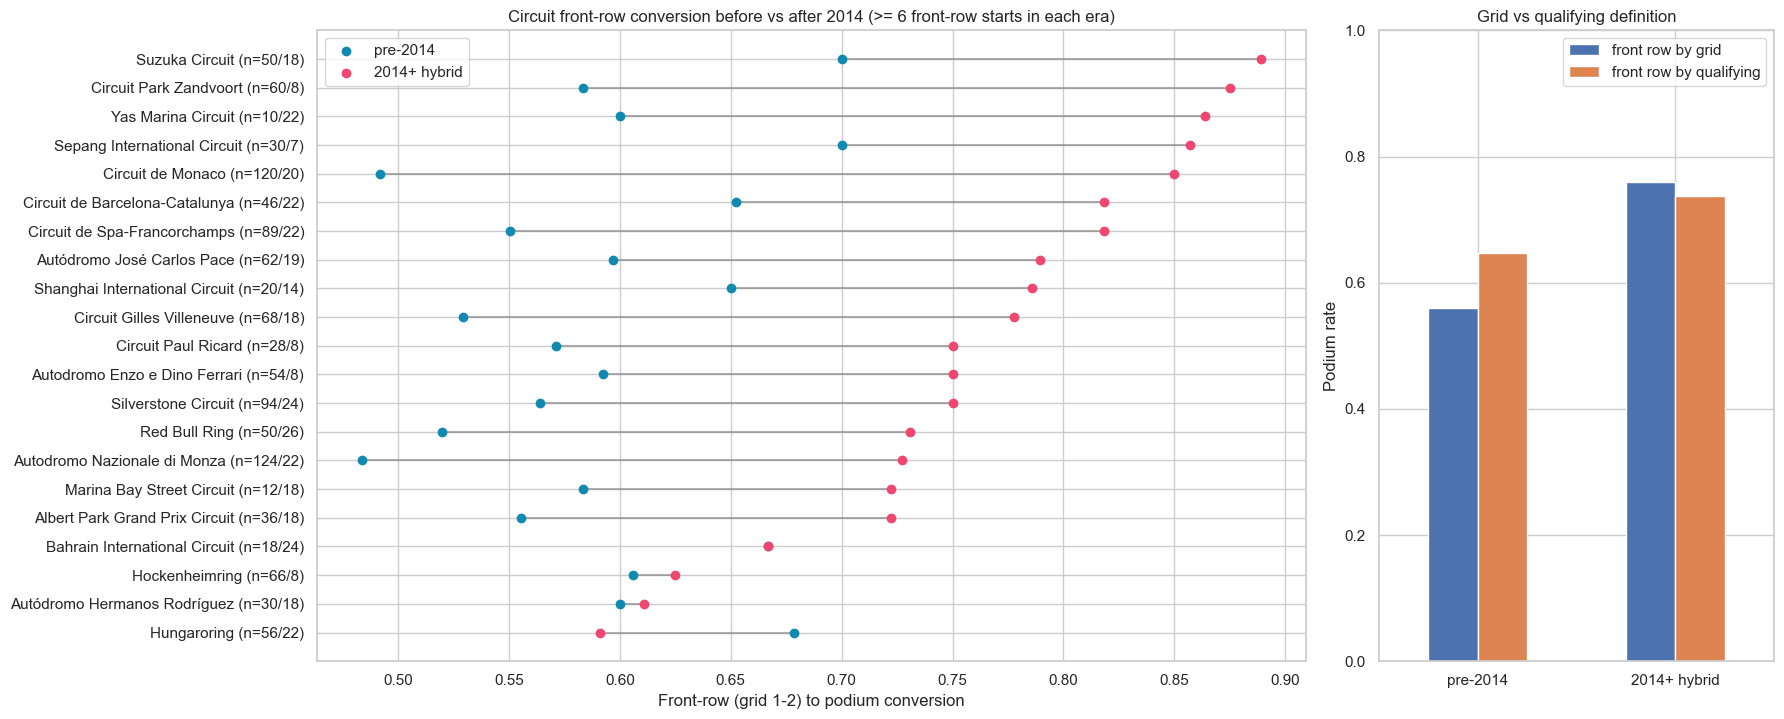

**DE Question 1 answer.** Across 21 circuits with at least 6 front-row starts in both eras, the highest 2014+ conversion is at Suzuka Circuit (89%), Circuit Park Zandvoort (88%), Yas Marina Circuit (86%); before 2014 the leaders were Suzuka Circuit (70%), Sepang International Circuit (70%), Hungaroring (68%). Overall front-row conversion moved from 56.0% to 76.0%. The circuit ranking is only weakly preserved (Spearman rank correlation 0.06); the largest shifts are Circuit de Monaco (+36%), Circuit Park Zandvoort (+29%), Circuit de Spa-Francorchamps (+27%).

**Grain and definitions.** One row per driver-race from the unique driver-race base; a front-row start is starting grid 1-2. Grid and qualifying are kept as separate columns because grid penalties move cars after qualifying: 38 drivers qualified on the front row but started elsewhere. The final result is used only to define the podium outcome. **Missing qualifying coverage:** only 30% of pre-2014 front-row starts have a qualifying row (vs 100% after 2014), so the circuit comparison uses grid, which is available in every era. Small per-circuit samples (n shown on the axis) make individual rates noisy.

In [6]:
q1 = (
    results_one[["raceId", "driverId", "grid", "podium"]]
    .merge(tables["races"][["raceId", "year", "circuitId"]], on="raceId", how="left")
    .merge(tables["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId", how="left")
    .merge(tables["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "qualifying_position"}),
           on=["raceId", "driverId"], how="left")
)
assert len(q1) == len(results_one)
q1["era"] = np.where(q1["year"] >= 2014, "2014+ hybrid", "pre-2014")
q1["front_row_grid"] = q1["grid"].between(1, 2)
q1["front_row_qualifying"] = q1["qualifying_position"].between(1, 2)
front = q1[q1["front_row_grid"]]
ERAS = ["pre-2014", "2014+ hybrid"]
MIN_STARTS_PER_ERA = 6

q1_coverage = pd.DataFrame(
    {
        era: {
            "front_row_starts (grid 1-2)": int(d["front_row_grid"].sum()),
            "front_row_podium_rate": d.loc[d["front_row_grid"], "podium"].mean(),
            "front_row_starts_with_qualifying_row": d.loc[d["front_row_grid"], "qualifying_position"].notna().mean(),
            "qualified_front_row_but_started_elsewhere": int((d["front_row_qualifying"] & ~d["front_row_grid"]).sum()),
            "podium_rate_front_row_by_qualifying": d.loc[d["front_row_qualifying"], "podium"].mean(),
        }
        for era, d in q1.groupby("era")
    }
).T.reindex(ERAS)

circuit_era = (
    front.groupby(["circuit", "era"]).agg(starts=("podium", "size"), podiums=("podium", "sum")).reset_index()
    .assign(rate=lambda d: d["podiums"] / d["starts"])
    .pivot(index="circuit", columns="era", values=["starts", "rate"])
)
circuit_era.columns = [f"{metric}_{era}" for metric, era in circuit_era.columns]
q1_table = circuit_era.dropna()
q1_table = q1_table[(q1_table[f"starts_{ERAS[0]}"] >= MIN_STARTS_PER_ERA) & (q1_table[f"starts_{ERAS[1]}"] >= MIN_STARTS_PER_ERA)].copy()
q1_table["change"] = q1_table[f"rate_{ERAS[1]}"] - q1_table[f"rate_{ERAS[0]}"]
for era in ERAS:
    q1_table[f"rank_{era}"] = q1_table[f"rate_{era}"].rank(ascending=False, method="min").astype(int)
q1_table = q1_table.sort_values(f"rate_{ERAS[1]}", ascending=False)
rank_corr = q1_table[f"rate_{ERAS[0]}"].corr(q1_table[f"rate_{ERAS[1]}"], method="spearman")

display(q1_coverage.round(3))
display(q1_table.round(3))
q1_table.to_csv(CLEANED_DIR / "deq1_front_row_conversion.csv")

fig, axes = plt.subplots(1, 2, figsize=(18, max(6, 0.35 * len(q1_table))), gridspec_kw={"width_ratios": [3, 1.2]})
y = np.arange(len(q1_table))
axes[0].hlines(y, q1_table[f"rate_{ERAS[0]}"], q1_table[f"rate_{ERAS[1]}"], color="gray", alpha=0.6)
axes[0].scatter(q1_table[f"rate_{ERAS[0]}"], y, color="#118ab2", label="pre-2014", zorder=3)
axes[0].scatter(q1_table[f"rate_{ERAS[1]}"], y, color="#ef476f", label="2014+ hybrid", zorder=3)
axes[0].set_yticks(y, [f"{c} (n={int(a)}/{int(b)})" for c, a, b in zip(q1_table.index, q1_table[f"starts_{ERAS[0]}"], q1_table[f"starts_{ERAS[1]}"])])
axes[0].invert_yaxis()
axes[0].set_xlabel("Front-row (grid 1-2) to podium conversion")
axes[0].set_title(f"Circuit front-row conversion before vs after 2014 (>= {MIN_STARTS_PER_ERA} front-row starts in each era)")
axes[0].legend()
q1_coverage[["front_row_podium_rate", "podium_rate_front_row_by_qualifying"]].rename(
    columns={"front_row_podium_rate": "front row by grid", "podium_rate_front_row_by_qualifying": "front row by qualifying"}
).plot.bar(ax=axes[1], rot=0)
axes[1].set_ylim(0, 1)
axes[1].set_title("Grid vs qualifying definition")
axes[1].set_ylabel("Podium rate")
plt.tight_layout()
plt.show()

top_pre = q1_table.sort_values(f"rate_{ERAS[0]}", ascending=False).head(3)
top_post = q1_table.head(3)
biggest = q1_table.reindex(q1_table["change"].abs().sort_values(ascending=False).index).head(3)
q1_answer = (
    f"Across {len(q1_table)} circuits with at least {MIN_STARTS_PER_ERA} front-row starts in both eras, the highest 2014+ conversion is at "
    f"{', '.join(f'{c} ({r:.0%})' for c, r in top_post[f'rate_{ERAS[1]}'].items())}; before 2014 the leaders were "
    f"{', '.join(f'{c} ({r:.0%})' for c, r in top_pre[f'rate_{ERAS[0]}'].items())}. "
    f"Overall front-row conversion moved from {q1_coverage.loc[ERAS[0], 'front_row_podium_rate']:.1%} to {q1_coverage.loc[ERAS[1], 'front_row_podium_rate']:.1%}. "
    f"The circuit ranking is only weakly preserved (Spearman rank correlation {rank_corr:.2f}); the largest shifts are "
    f"{', '.join(f'{c} ({d:+.0%})' for c, d in biggest['change'].items())}."
)
note(
    "**DE Question 1 answer.** " + q1_answer + "\n\n"
    "**Grain and definitions.** One row per driver-race from the unique driver-race base; a front-row start is starting grid 1-2. "
    "Grid and qualifying are kept as separate columns because grid penalties move cars after qualifying: "
    f"{int(q1_coverage['qualified_front_row_but_started_elsewhere'].sum())} drivers qualified on the front row but started elsewhere. "
    "The final result is used only to define the podium outcome. "
    f"**Missing qualifying coverage:** only {q1_coverage.loc[ERAS[0], 'front_row_starts_with_qualifying_row']:.0%} of pre-2014 front-row starts have a "
    f"qualifying row (vs {q1_coverage.loc[ERAS[1], 'front_row_starts_with_qualifying_row']:.0%} after 2014), so the circuit comparison uses grid, which is "
    "available in every era. Small per-circuit samples (n shown on the axis) make individual rates noisy."
)

# Part B — Pre-race feature plan, leakage-safe modeling table, Data-Engineering Questions 3 and 2

In [7]:
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina", "Argentinian": "Argentina",
    "Argentine-Italian": "Argentina", "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China",
    "Colombian": "Colombia", "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands",
    "East German": "Germany", "Finnish": "Finland", "French": "France", "German": "Germany", "Hungarian": "Hungary",
    "Indian": "India", "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Zimbabwe",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
COUNTRY_ALIASES = {"United States": "USA", "United Kingdom": "UK", "Great Britain": "UK", "United Arab Emirates": "UAE", "South Korea": "Korea"}


def nationality_to_country(value):
    return np.nan if pd.isna(value) else NATIONALITY_TO_COUNTRY.get(str(value).strip(), np.nan)


def normalize_country(value):
    return np.nan if pd.isna(value) else COUNTRY_ALIASES.get(str(value).strip(), str(value).strip())


def as_category(series):
    return series.map(
        lambda v: np.nan if pd.isna(v) else str(int(v)) if isinstance(v, (int, float, np.integer, np.floating)) else str(v)
    ).astype(object)


races_ctx = tables["races"][["raceId", "year", "round", "circuitId", "date"]]
model_df = (
    results_one[["raceId", "driverId", "constructorId", "grid", "podium"]]
    .merge(races_ctx, on="raceId", how="left")
    .merge(tables["circuits"][["circuitId", "country", "lat", "lng", "alt"]], on="circuitId", how="left")
    .merge(tables["drivers"][["driverId", "dob", "nationality"]].rename(columns={"nationality": "driverNationality"}), on="driverId", how="left")
    .merge(tables["constructors"][["constructorId", "nationality"]].rename(columns={"nationality": "constructorNationality"}), on="constructorId", how="left")
)
model_df["grid_position"] = model_df["grid"].where(model_df["grid"] > 0)
model_df["grid_zero_or_unknown"] = (model_df["grid"].fillna(0) <= 0).astype(int)
model_df["driverAgeYears"] = (model_df["date"] - model_df["dob"]).dt.days / 365.25
model_df["circuitCountryNorm"] = model_df["country"].map(normalize_country)
model_df["driver_home_race"] = (model_df["driverNationality"].map(nationality_to_country) == model_df["circuitCountryNorm"]).astype(int)

qualifying_feat = tables["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].rename(columns={"position": "qualifying_position"})
qualifying_feat["best_qualifying_sec"] = qualifying_feat[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
qualifying_feat["completed_q3"] = qualifying_feat["q3_sec"].notna().astype(int)
model_df = model_df.merge(qualifying_feat, on=["raceId", "driverId"], how="left")
model_df["qualifying_missing"] = model_df["qualifying_position"].isna().astype(int)
model_df["qualifying_gap_to_pole"] = model_df["best_qualifying_sec"] - model_df.groupby("raceId")["best_qualifying_sec"].transform("min")
model_df["qualifying_position_delta_to_grid"] = model_df["grid_position"] - model_df["qualifying_position"]


def previous_standings(standings, entity, prefix):
    st = standings[["raceId", entity, "points", "position", "wins"]].merge(races_ctx[["raceId", "year", "round"]], on="raceId")
    st = st.sort_values(["year", "round"])
    shifted = st.groupby(["year", entity])[["points", "position", "wins"]].shift(1)
    return pd.concat([st[["raceId", entity]], shifted.add_prefix(f"{prefix}_prev_")], axis=1)


model_df = model_df.merge(previous_standings(tables["driver_standings"], "driverId", "driver"), on=["raceId", "driverId"], how="left")
model_df = model_df.merge(previous_standings(tables["constructor_standings"], "constructorId", "constructor"), on=["raceId", "constructorId"], how="left")


def prior_rolling_mean(series, window=5):
    return series.shift(1).rolling(window, min_periods=1).mean()


history = (
    results_one[["raceId", "driverId", "constructorId", "positionOrder", "points", "podium"]]
    .merge(races_ctx[["raceId", "date"]], on="raceId")
    .sort_values(["date", "raceId", "driverId"])
)
for source, target in [("podium", "podium_rate_5"), ("positionOrder", "avg_finish_5"), ("points", "points_5")]:
    history[f"driver_form_{target}"] = history.groupby("driverId")[source].transform(prior_rolling_mean)
constructor_history = (
    history.groupby(["constructorId", "raceId", "date"], as_index=False)
    .agg(podium=("podium", "mean"), positionOrder=("positionOrder", "mean"), points=("points", "sum"))
    .sort_values(["date", "raceId"])
)
for source, target in [("podium", "podium_rate_5"), ("positionOrder", "avg_finish_5"), ("points", "points_5")]:
    constructor_history[f"constructor_form_{target}"] = constructor_history.groupby("constructorId")[source].transform(prior_rolling_mean)
model_df = model_df.merge(history[["raceId", "driverId"] + [c for c in history if c.startswith("driver_form_")]], on=["raceId", "driverId"], how="left")
model_df = model_df.merge(
    constructor_history[["raceId", "constructorId"] + [c for c in constructor_history if c.startswith("constructor_form_")]],
    on=["raceId", "constructorId"], how="left",
)

FEATURE_GROUPS = {
    "grid": ["grid_position", "grid_zero_or_unknown"],
    "qualifying": ["qualifying_position", "q1_sec", "q2_sec", "q3_sec", "best_qualifying_sec", "completed_q3",
                   "qualifying_missing", "qualifying_gap_to_pole", "qualifying_position_delta_to_grid"],
    "standings": ["driver_prev_points", "driver_prev_position", "driver_prev_wins",
                  "constructor_prev_points", "constructor_prev_position", "constructor_prev_wins"],
    "form": ["driver_form_podium_rate_5", "driver_form_avg_finish_5", "driver_form_points_5",
             "constructor_form_podium_rate_5", "constructor_form_avg_finish_5", "constructor_form_points_5"],
    "context": ["year", "round", "driverAgeYears", "driver_home_race", "lat", "lng", "alt",
                "circuitId", "driverNationality", "constructorNationality", "circuitCountryNorm"],
}
categorical_features = ["circuitId", "driverNationality", "constructorNationality", "circuitCountryNorm"]
feature_columns = [c for cols in FEATURE_GROUPS.values() for c in cols]
numeric_features = [c for c in feature_columns if c not in categorical_features]
feature_group_of = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
for col in categorical_features:
    model_df[col] = as_category(model_df[col])
assert not model_df.duplicated(["raceId", "driverId"]).any() and len(model_df) == len(results_one)
print(f"{len(feature_columns)} candidate features ({len(numeric_features)} numeric, {len(categorical_features)} categorical) on {len(model_df):,} driver-race rows")

34 candidate features (30 numeric, 4 categorical) on 26,668 driver-race rows


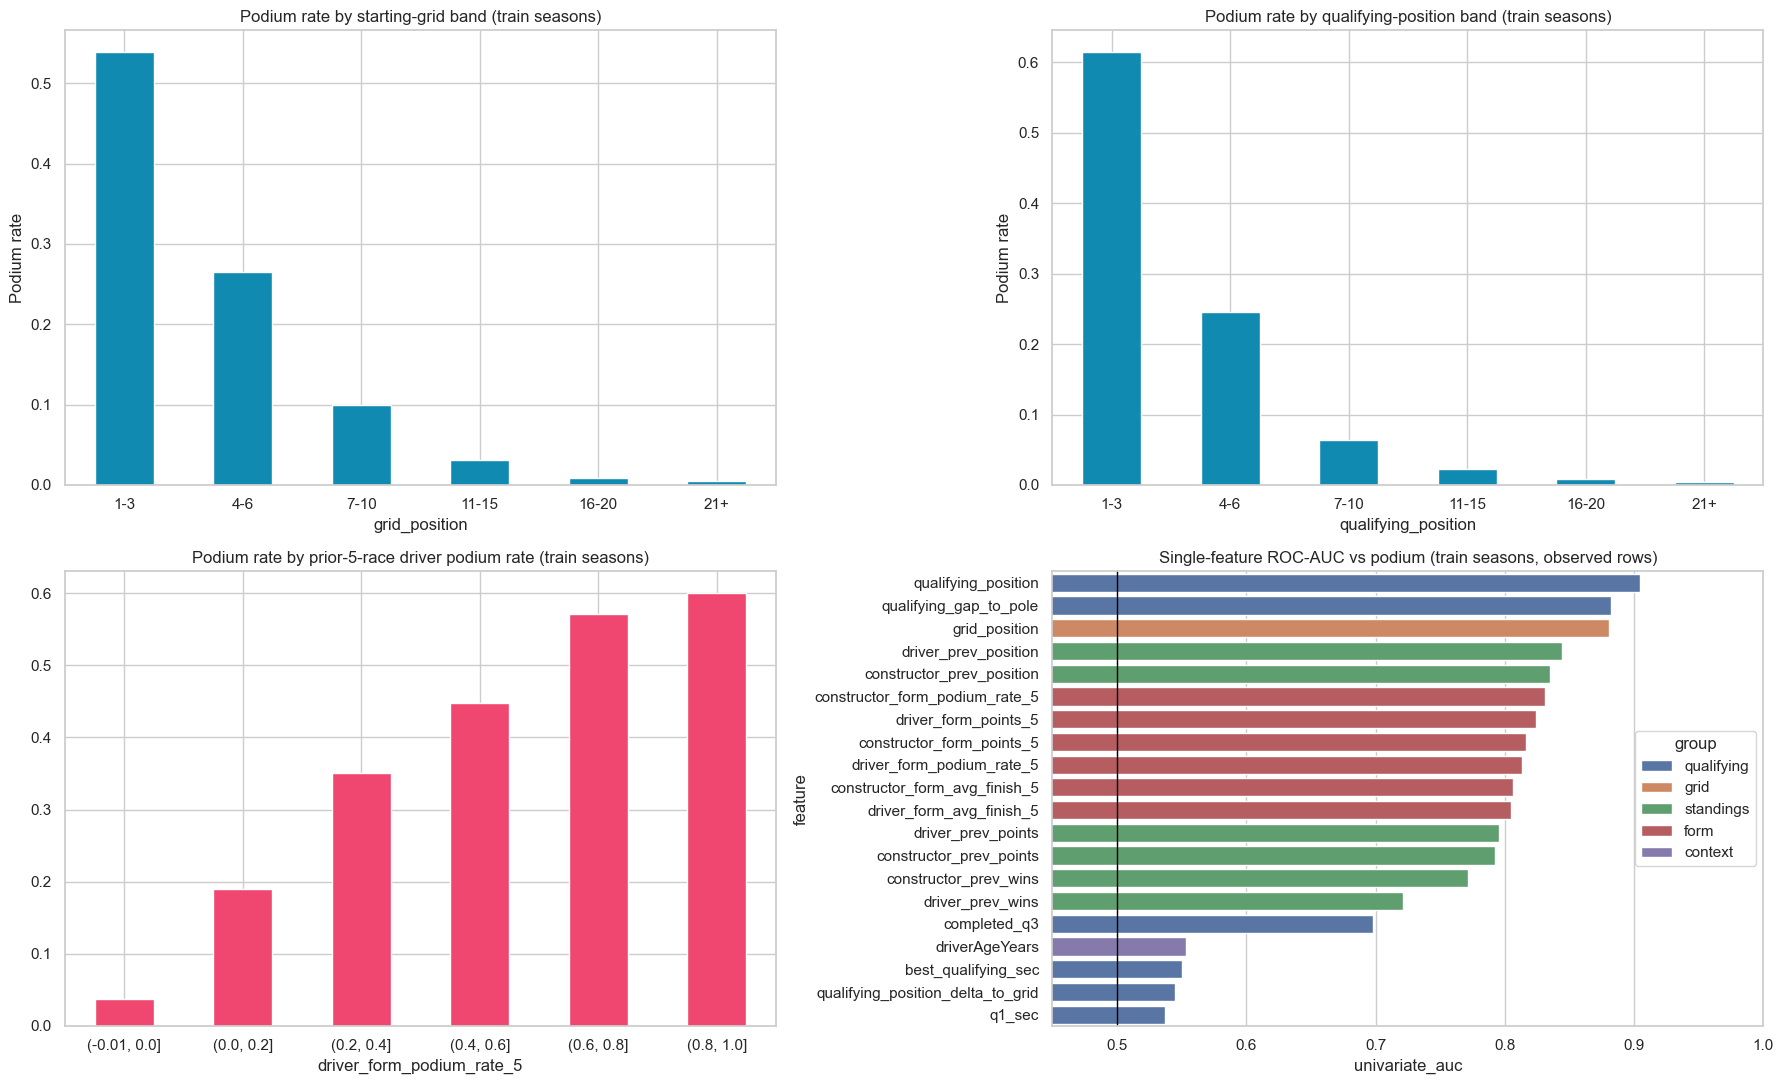

,group,features,available_at,why_available,best_univariate_auc,median_train_coverage
0,grid,"grid_position, grid_zero_or_unknown","post-qualifying, pre-race",Starting grid is published after qualifying an...,0.880,0.968
1,qualifying,"qualifying_position, q1_sec, q2_sec, q3_sec, b...","post-qualifying, pre-race",Qualifying positions and session times are fin...,0.905,0.324
2,standings,"driver_prev_points, driver_prev_position, driv...",before current race,Championship table after the previous round of...,0.844,0.856
3,form,"driver_form_podium_rate_5, driver_form_avg_fin...",before current race,Rolling mean of the previous 5 races only (shi...,0.831,0.975
4,context,"year, round, driverAgeYears, driver_home_race,...",known before the weekend,"Calendar, circuit geography, age, nationalitie...",0.553,1.000


,excluded group,columns
0,current-race results,"position, positionText, positionOrder, time, m..."
1,current-race status,"statusId, status"
2,current-race points,points
3,current-race laps,"laps, lap_times.*"
4,pit stops,pit_stops.*
5,post-race standings,driver_standings / constructor_standings at th...
6,identity IDs (memorise past drivers/teams),"driverId, constructorId"


**Feature plan (evidence from training seasons only, so the test era never influences selection).** Grid and qualifying are the strongest single signals (best single-feature AUC 0.88 / 0.90) with a steep podium-rate drop beyond P3; prior form and prior standings add car/driver strength that the grid alone does not carry; qualifying features cover only 32% of training rows (median), so they are paired with `qualifying_missing`/`completed_q3` flags. **`driverId` and `constructorId` are excluded as predictors:** one-hot IDs memorise which drivers and teams won historically, which does not transfer to new seasons and new entrants (the Part C ablation re-adds them to quantify this; this changes Part B's original feature list and should be confirmed by the team). Every current-race outcome, status, points, laps, pit stops and post-race standings are excluded.

In [8]:
TRAIN_END_YEAR = 2018
evidence = model_df[model_df["year"] <= TRAIN_END_YEAR]


def univariate_strength(col):
    sub = evidence[[col, "podium"]].dropna()
    auc = roc_auc_score(sub["podium"], sub[col]) if sub[col].nunique() > 1 else np.nan
    return {"feature": col, "group": feature_group_of[col], "coverage": evidence[col].notna().mean(),
            "univariate_auc": max(auc, 1 - auc), "direction": "higher -> podium" if auc >= 0.5 else "lower -> podium"}


univariate = pd.DataFrame([univariate_strength(c) for c in numeric_features]).sort_values("univariate_auc", ascending=False)

BANDS = dict(bins=[0, 3, 6, 10, 15, 20, 99], labels=["1-3", "4-6", "7-10", "11-15", "16-20", "21+"])
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, col, title in [(axes[0, 0], "grid_position", "starting-grid band"), (axes[0, 1], "qualifying_position", "qualifying-position band")]:
    rates = evidence.groupby(pd.cut(evidence[col], **BANDS), observed=True)["podium"].mean()
    rates.plot.bar(ax=ax, rot=0, color="#118ab2")
    ax.set_title(f"Podium rate by {title} (train seasons)")
    ax.set_ylabel("Podium rate")
form_bins = pd.cut(evidence["driver_form_podium_rate_5"], [-0.01, 0, 0.2, 0.4, 0.6, 0.8, 1.0])
evidence.groupby(form_bins, observed=True)["podium"].mean().plot.bar(ax=axes[1, 0], rot=0, color="#ef476f")
axes[1, 0].set_title("Podium rate by prior-5-race driver podium rate (train seasons)")
axes[1, 0].set_xlabel("driver_form_podium_rate_5")
sns.barplot(data=univariate.head(20), x="univariate_auc", y="feature", hue="group", dodge=False, ax=axes[1, 1])
axes[1, 1].axvline(0.5, color="black", linewidth=1)
axes[1, 1].set_xlim(0.45, 1)
axes[1, 1].set_title("Single-feature ROC-AUC vs podium (train seasons, observed rows)")
plt.tight_layout()
plt.show()

AVAILABILITY = {
    "grid": ("post-qualifying, pre-race", "Starting grid is published after qualifying and penalties, before lights out."),
    "qualifying": ("post-qualifying, pre-race", "Qualifying positions and session times are final before the race."),
    "standings": ("before current race", "Championship table after the previous round of the same season (shift by one race)."),
    "form": ("before current race", "Rolling mean of the previous 5 races only (shift(1) before rolling)."),
    "context": ("known before the weekend", "Calendar, circuit geography, age, nationalities and home-race flag are static or scheduled."),
}
feature_plan = pd.DataFrame(
    [
        {
            "group": g,
            "features": ", ".join(cols),
            "available_at": AVAILABILITY[g][0],
            "why_available": AVAILABILITY[g][1],
            "best_univariate_auc": univariate.loc[univariate["group"] == g, "univariate_auc"].max(),
            "median_train_coverage": univariate.loc[univariate["group"] == g, "coverage"].median(),
        }
        for g, cols in FEATURE_GROUPS.items()
    ]
)
EXCLUDED_PREDICTORS = {
    "current-race results": ["position", "positionText", "positionOrder", "time", "milliseconds", "race_time_sec",
                             "fastestLap", "rank", "fastestLapTime", "fastestLapTime_sec", "fastestLapSpeed"],
    "current-race status": ["statusId", "status"],
    "current-race points": ["points"],
    "current-race laps": ["laps", "lap_times.*"],
    "pit stops": ["pit_stops.*"],
    "post-race standings": ["driver_standings / constructor_standings at the current raceId (unshifted)"],
    "identity IDs (memorise past drivers/teams)": ["driverId", "constructorId"],
}
FORBIDDEN_COLUMNS = {c for cols in EXCLUDED_PREDICTORS.values() for c in cols if "." not in c and " " not in c}
assert not FORBIDDEN_COLUMNS & set(feature_columns)
display(feature_plan.round(3))
display(pd.DataFrame([(k, ", ".join(v)) for k, v in EXCLUDED_PREDICTORS.items()], columns=["excluded group", "columns"]))
feature_plan.to_csv(CLEANED_DIR / "feature_plan.csv", index=False)
note(
    "**Feature plan (evidence from training seasons only, so the test era never influences selection).** "
    f"Grid and qualifying are the strongest single signals (best single-feature AUC {feature_plan.set_index('group').loc['grid', 'best_univariate_auc']:.2f} / "
    f"{feature_plan.set_index('group').loc['qualifying', 'best_univariate_auc']:.2f}) with a steep podium-rate drop beyond P3; prior form and prior standings add "
    "car/driver strength that the grid alone does not carry; qualifying features cover only "
    f"{feature_plan.set_index('group').loc['qualifying', 'median_train_coverage']:.0%} of training rows (median), so they are paired with "
    "`qualifying_missing`/`completed_q3` flags. **`driverId` and `constructorId` are excluded as predictors:** one-hot IDs memorise which drivers "
    "and teams won historically, which does not transfer to new seasons and new entrants (the Part C ablation re-adds them to quantify this; "
    "this changes Part B's original feature list and should be confirmed by the team). Every current-race outcome, status, points, laps, "
    "pit stops and post-race standings are excluded."
)

In [9]:
KEY_COLUMNS = ["raceId", "driverId", "constructorId"]
modeling_data = model_df[KEY_COLUMNS + feature_columns + ["podium"]].copy()

feature_dictionary = pd.DataFrame(
    [
        {"column": c, "role": "row key (not a predictor)", "group": "key", "dtype": str(modeling_data[c].dtype),
         "available_at": "pre-race", "missing_pct": modeling_data[c].isna().mean()}
        for c in KEY_COLUMNS
    ]
    + [
        {"column": c, "role": "predictor (categorical)" if c in categorical_features else "predictor (numeric)",
         "group": feature_group_of[c], "dtype": str(modeling_data[c].dtype),
         "available_at": AVAILABILITY[feature_group_of[c]][0], "missing_pct": modeling_data[c].isna().mean()}
        for c in feature_columns
    ]
    + [{"column": "podium", "role": "outcome (positionOrder <= 3), never a predictor", "group": "target",
        "dtype": str(modeling_data["podium"].dtype), "available_at": "post-race", "missing_pct": modeling_data["podium"].isna().mean()}]
)

first_driver_race = history.groupby("driverId").head(1)
first_constructor_race = constructor_history.groupby("constructorId").head(1)
validation_checks = pd.DataFrame(
    [
        ("one row per (raceId, driverId)", not modeling_data.duplicated(["raceId", "driverId"]).any()),
        ("row count equals unique driver-race base", len(modeling_data) == len(results_one)),
        ("row keys non-null", modeling_data[KEY_COLUMNS].notna().all().all()),
        ("target is binary and complete", set(modeling_data["podium"].unique()) <= {0, 1} and modeling_data["podium"].notna().all()),
        ("target not among predictors", "podium" not in feature_columns),
        ("no current-race / post-race columns among predictors", not FORBIDDEN_COLUMNS & set(feature_columns)),
        ("every predictor has a pre-race availability", feature_dictionary.loc[feature_dictionary["role"].str.startswith("predictor"), "available_at"].ne("post-race").all()),
        ("driver form is missing on each driver's first race (shifted)", first_driver_race["driver_form_podium_rate_5"].isna().all()),
        ("constructor form is missing on each constructor's first race (shifted)", first_constructor_race["constructor_form_podium_rate_5"].isna().all()),
        ("previous standings are missing in round 1 (shifted)", modeling_data.loc[modeling_data["round"] == 1, ["driver_prev_points", "constructor_prev_points"]].isna().all().all()),
        ("no predictor is entirely missing", modeling_data[feature_columns].notna().any().all()),
    ],
    columns=["check", "passes"],
)
assert validation_checks["passes"].all(), validation_checks[~validation_checks["passes"]]

modeling_data.to_csv(CLEANED_DIR / "modeling_table.csv", index=False)
feature_dictionary.to_csv(CLEANED_DIR / "feature_dictionary.csv", index=False)
validation_checks.to_csv(CLEANED_DIR / "modeling_validation_checks.csv", index=False)
display(validation_checks)
display(feature_dictionary.sort_values("missing_pct", ascending=False).round(3))
print(f"Modeling table: {len(modeling_data):,} rows, {modeling_data['raceId'].nunique():,} races, podium rate {modeling_data['podium'].mean():.3f}")

,check,passes
0,"one row per (raceId, driverId)",True
1,row count equals unique driver-race base,True
2,row keys non-null,True
3,target is binary and complete,True
4,target not among predictors,True
5,no current-race / post-race columns among pred...,True
6,every predictor has a pre-race availability,True
7,driver form is missing on each driver's first ...,True
8,constructor form is missing on each constructo...,True
9,previous standings are missing in round 1 (shi...,True


,column,role,group,dtype,available_at,missing_pct
8,q3_sec,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.864
7,q2_sec,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.781
6,q1_sec,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.612
9,best_qualifying_sec,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.612
12,qualifying_gap_to_pole,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.612
13,qualifying_position_delta_to_grid,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.610
5,qualifying_position,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.606
10,completed_q3,predictor (numeric),qualifying,float64,"post-qualifying, pre-race",0.606
14,driver_prev_points,predictor (numeric),standings,float64,before current race,0.137
16,driver_prev_wins,predictor (numeric),standings,float64,before current race,0.137


Modeling table: 26,668 rows, 1,125 races, podium rate 0.127


,statuses (2014-2024),rows_2014_2024
category,,
crash or contact,"Collision, Accident, Collision damage, Spun of...",308
did not start,Withdrew,14
driver or medical,Illness,3
finished,"Finished, +1 Lap, +2 Laps, +3 Laps, +4 Laps, +...",3825
mechanical,"Engine, Brakes, Gearbox, Power Unit, Suspensio...",399
regulation,"Disqualified, Excluded",12
uncertain,"Retired, Puncture, Tyre, Front wing, Out of fuel",65


,period,constructor,starts,mechanical,uncertain,lap0_mechanical,mechanical_rate,upper_bound_rate
4,2014-2021,Caterham,34,8,3,1,0.235,0.324
8,2014-2021,Lotus F1,75,14,4,1,0.187,0.240
17,2014-2021,Toro Rosso,242,39,5,1,0.161,0.182
11,2014-2021,McLaren,318,46,5,4,0.145,0.160
15,2014-2021,Renault,200,28,4,2,0.140,0.160
16,2014-2021,Sauber,200,22,5,2,0.110,0.135
14,2014-2021,Red Bull,319,34,4,0,0.107,0.119
1,2014-2021,AlphaTauri,78,8,1,1,0.103,0.115
10,2014-2021,Marussia,31,3,0,0,0.097,0.097
7,2014-2021,Haas F1 Team,241,23,6,0,0.095,0.120


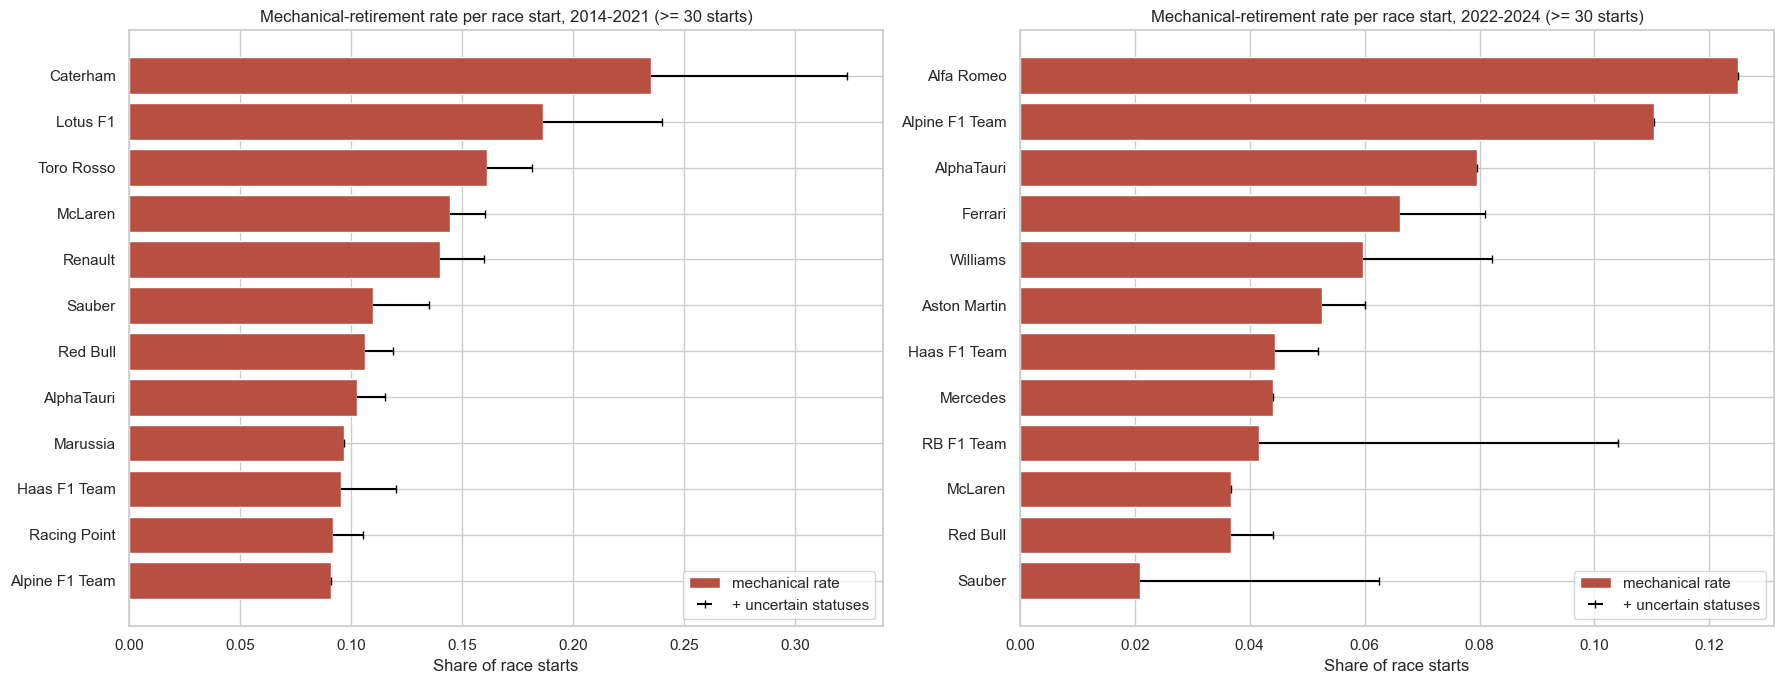

**DE Question 3 answer.** Highest mechanical-retirement rates: 2014-2021: Caterham 23.5% (8/34), Lotus F1 18.7% (14/75), Toro Rosso 16.1% (39/242); 2022-2024: Alfa Romeo 12.5% (11/88), Alpine F1 Team 11.0% (15/136), AlphaTauri 8.0% (7/88). Across all constructors the rate fell from 9.7% of starts in 2014-2021 to 6.1% in 2022-2024.

**Definition.** A mechanical retirement is a race start whose status names a failed car component (engine, power unit, gearbox, hydraulics, brakes, ...). Crash/contact outcomes (accident, collision, damage, debris), driver/medical outcomes, regulation outcomes (disqualified, excluded) and finishes are excluded. **Denominator:** race starts = driver-race rows in the period except 'did not start' statuses (Withdrew, DNS, DNQ). The full status-to-category table is shown above and saved with the outputs. **Uncertainty:** generic statuses ('Retired', 'Puncture', 'Tyre', 'Front wing', 'Out of fuel') cannot be attributed to a component; the black whisker shows each constructor's rate if they were all mechanical. Rows with 0 laps completed and a mechanical status (24 in the plotted constructors) may be formation-lap failures and are kept as starts. Constructors with fewer than 30 starts in a period are not ranked; rebrands (e.g. Renault to Alpine) are separate constructors in the source data.

In [10]:
NON_START = {"Did not qualify", "Did not prequalify", "Did not start", "Withdrew", "107% Rule", "Not qualified"}
REGULATION = {"Disqualified", "Excluded", "Underweight", "Safety concerns", "Safety"}
CRASH_OR_CONTACT = {"Accident", "Collision", "Collision damage", "Spun off", "Damage", "Debris", "Fatal accident"}
DRIVER_OR_MEDICAL = {"Illness", "Injury", "Injured", "Eye injury", "Physical", "Driver unwell"}
UNCERTAIN = {"Retired", "Puncture", "Tyre", "Tyre puncture", "Front wing", "Out of fuel", "Not classified", "Handling", "Stalled", "Not restarted"}
MECHANICAL_KEYWORDS = [
    "engine", "gearbox", "transmission", "clutch", "hydraulic", "electric", "electronic", "fuel", "oil", "brake",
    "suspension", "power", "alternator", "battery", "turbo", "ers", "mgu", "water", "radiator", "overheat", "pneumatic",
    "driveshaft", "drivetrain", "halfshaft", "wheel", "throttle", "steering", "exhaust", "ignition", "spark", "differential",
    "cv joint", "pump", "mechanical", "technical", "vibration", "undertray", "rear wing", "seat", "cooling", "axle",
    "chassis", "magneto", "distributor", "injection", "crankshaft", "supercharger", "launch control", "fire",
]


def status_category(status):
    if status == "Finished" or re.fullmatch(r"\+\d+ Laps?", status):
        return "finished"
    for category, labels in [("did not start", NON_START), ("regulation", REGULATION), ("crash or contact", CRASH_OR_CONTACT),
                             ("driver or medical", DRIVER_OR_MEDICAL), ("uncertain", UNCERTAIN)]:
        if status in labels:
            return category
    if any(k in status.lower() for k in MECHANICAL_KEYWORDS):
        return "mechanical"
    return "unmapped"


status_map = tables["status"].assign(category=lambda d: d["status"].map(status_category))
q3 = (
    results_one[["raceId", "driverId", "constructorId", "statusId", "laps"]]
    .merge(tables["races"][["raceId", "year"]], on="raceId", how="left")
    .merge(tables["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
    .merge(status_map, on="statusId", how="left")
)
q3["period"] = q3["year"].map(lambda y: "2014-2021" if 2014 <= y <= 2021 else "2022-2024" if 2022 <= y <= 2024 else None)
q3 = q3[q3["period"].notna()]
assert q3["category"].ne("unmapped").all() and q3["status"].notna().all(), q3.loc[q3["category"].eq("unmapped"), "status"].unique()

mapping_used = q3.groupby(["category", "status"]).size().rename("rows_2014_2024").reset_index().sort_values(["category", "rows_2014_2024"], ascending=[True, False])
starts = q3[q3["category"] != "did not start"].assign(
    mechanical=lambda d: d["category"] == "mechanical",
    uncertain=lambda d: d["category"] == "uncertain",
    lap0_mechanical=lambda d: (d["category"] == "mechanical") & (d["laps"] == 0),
)
MIN_STARTS = 30
q3_rates = (
    starts.groupby(["period", "constructor"])
    .agg(starts=("category", "size"), mechanical=("mechanical", "sum"), uncertain=("uncertain", "sum"), lap0_mechanical=("lap0_mechanical", "sum"))
    .reset_index()
)
q3_rates["mechanical_rate"] = q3_rates["mechanical"] / q3_rates["starts"]
q3_rates["upper_bound_rate"] = (q3_rates["mechanical"] + q3_rates["uncertain"]) / q3_rates["starts"]
q3_rates = q3_rates[q3_rates["starts"] >= MIN_STARTS].sort_values(["period", "mechanical_rate"], ascending=[True, False])

display(mapping_used.groupby("category")["status"].apply(", ".join).to_frame("statuses (2014-2024)").join(mapping_used.groupby("category")["rows_2014_2024"].sum()))
display(q3_rates.groupby("period").head(10).round(3))
q3_rates.to_csv(CLEANED_DIR / "deq3_mechanical_retirement_rates.csv", index=False)
mapping_used.to_csv(CLEANED_DIR / "deq3_status_mapping.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (period, part) in zip(axes, q3_rates.groupby("period")):
    part = part.head(12).iloc[::-1]
    ax.barh(part["constructor"], part["mechanical_rate"], color="#b85042", label="mechanical rate")
    ax.errorbar(part["upper_bound_rate"], part["constructor"], xerr=[part["upper_bound_rate"] - part["mechanical_rate"], np.zeros(len(part))],
                fmt="|", color="black", capsize=0, label="+ uncertain statuses")
    ax.set_title(f"Mechanical-retirement rate per race start, {period} (>= {MIN_STARTS} starts)")
    ax.set_xlabel("Share of race starts")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

top_by_period = q3_rates.groupby("period").head(3)
q3_answer = "; ".join(
    f"{period}: " + ", ".join(f"{r.constructor} {r.mechanical_rate:.1%} ({r.mechanical}/{r.starts})" for r in part.itertuples())
    for period, part in top_by_period.groupby("period")
)
overall = starts.groupby("period")["mechanical"].mean()
note(
    f"**DE Question 3 answer.** Highest mechanical-retirement rates: {q3_answer}. Across all constructors the rate fell from "
    f"{overall.get('2014-2021', np.nan):.1%} of starts in 2014-2021 to {overall.get('2022-2024', np.nan):.1%} in 2022-2024.\n\n"
    "**Definition.** A mechanical retirement is a race start whose status names a failed car component (engine, power unit, gearbox, "
    "hydraulics, brakes, ...). Crash/contact outcomes (accident, collision, damage, debris), driver/medical outcomes, regulation outcomes "
    "(disqualified, excluded) and finishes are excluded. **Denominator:** race starts = driver-race rows in the period except "
    "'did not start' statuses (Withdrew, DNS, DNQ). The full status-to-category table is shown above and saved with the outputs. "
    "**Uncertainty:** generic statuses ('Retired', 'Puncture', 'Tyre', 'Front wing', 'Out of fuel') cannot be attributed to a component; "
    "the black whisker shows each constructor's rate if they were all mechanical. Rows with 0 laps completed and a mechanical status "
    f"({int(q3_rates['lap0_mechanical'].sum())} in the plotted constructors) may be formation-lap failures and are kept as starts. "
    f"Constructors with fewer than {MIN_STARTS} starts in a period are not ranked; rebrands (e.g. Renault to Alpine) are separate constructors in the source data."
)

,item,rows,share
0,driver nationality missing or unmapped,0,0.0000
1,circuit country missing,0,0.0000
2,grid = 0 / missing (no starting position to co...,1635,0.0613
3,driver country never hosts a race (cannot be '...,2471,0.0927


,grid_band,home_race,starts,podiums,podium_rate
0,1-3,False,3106,1725,0.555
1,1-3,True,264,145,0.549
2,4-6,False,3108,812,0.261
3,4-6,True,261,64,0.245
4,7-10,False,4124,385,0.093
5,7-10,True,387,34,0.088
6,11-15,False,5135,154,0.030
7,11-15,True,470,16,0.034
8,16-20,False,4737,41,0.009
9,16-20,True,498,3,0.006


/private/tmp/mi-f1-refactor/venv-kaggle/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/private/tmp/mi-f1-refactor/venv-kaggle/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


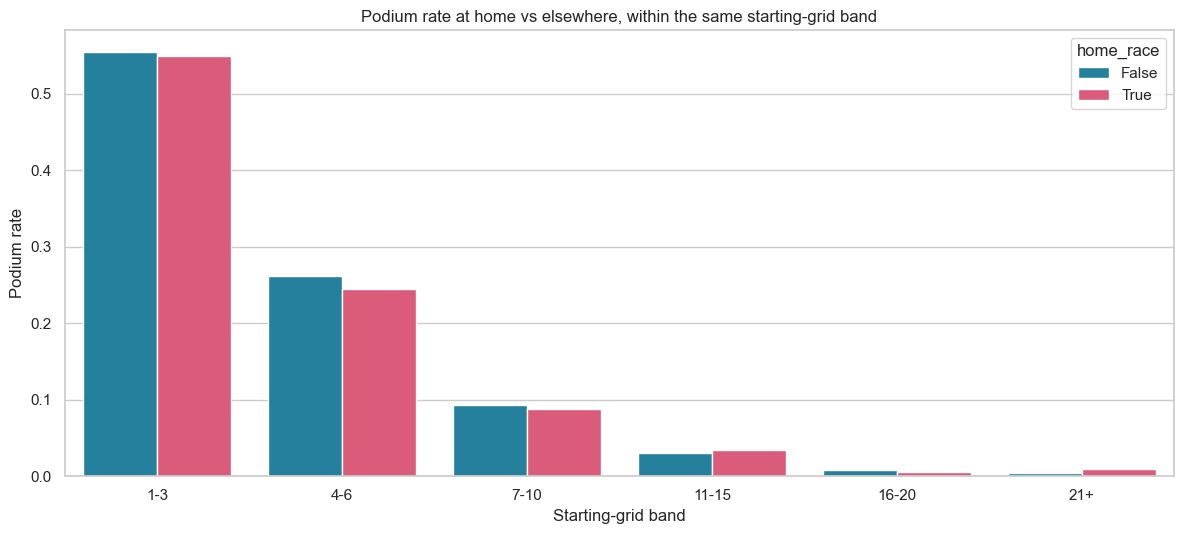

**DE Question 2 answer.** Crude podium rates are 0.115 at home vs 0.138 elsewhere, but home starts are not distributed like other starts across the grid. Standardised to the same grid-band mix, the home podium rate is 0.133 vs 0.136 elsewhere (-0.003); the Mantel-Haenszel grid-stratified odds ratio is 0.97.

**Control method.** Each driver-race start (25,033 rows with a known positive grid slot) is placed in one of six starting-grid bands; home and non-home podium rates are compared within each band, then combined with the same band weights (direct standardisation) and with a Mantel-Haenszel odds ratio. The final result is used only for the podium outcome. **Missing data:** see the table above; rows without a driver country, circuit country or positive grid are excluded. **Limitations:** 'home' is inferred from a single nationality (no dual nationality or residence), the nationality-to-country mapping is manual, home starts are a small minority, grid bands are coarse, and the comparison is associational, not causal.

In [11]:
q2 = (
    results_one[["raceId", "driverId", "grid", "podium"]]
    .merge(tables["races"][["raceId", "year", "circuitId"]], on="raceId", how="left")
    .merge(tables["circuits"][["circuitId", "country"]], on="circuitId", how="left")
    .merge(tables["drivers"][["driverId", "nationality"]], on="driverId", how="left")
)
q2["driver_country"] = q2["nationality"].map(nationality_to_country)
q2["circuit_country"] = q2["country"].map(normalize_country)
q2["grid_position"] = q2["grid"].where(q2["grid"] > 0)
q2_missing = pd.DataFrame(
    [
        ("driver nationality missing or unmapped", int(q2["driver_country"].isna().sum())),
        ("circuit country missing", int(q2["circuit_country"].isna().sum())),
        ("grid = 0 / missing (no starting position to control for)", int(q2["grid_position"].isna().sum())),
        ("driver country never hosts a race (cannot be 'home')", int((q2["driver_country"].notna() & ~q2["driver_country"].isin(q2["circuit_country"])).sum())),
    ],
    columns=["item", "rows"],
).assign(share=lambda d: d["rows"] / len(q2))

q2 = q2.dropna(subset=["driver_country", "circuit_country", "grid_position"]).copy()
q2["home_race"] = q2["driver_country"] == q2["circuit_country"]
q2["grid_band"] = pd.cut(q2["grid_position"], **BANDS)
q2_strata = (
    q2.groupby(["grid_band", "home_race"], observed=True)["podium"].agg(starts="size", podiums="sum").reset_index()
    .assign(podium_rate=lambda d: d["podiums"] / d["starts"])
)
wide = q2_strata.pivot(index="grid_band", columns="home_race", values=["starts", "podiums", "podium_rate"]).dropna()
band_weight = (wide["starts"][True] + wide["starts"][False]) / (wide["starts"][True] + wide["starts"][False]).sum()
std_home = float((wide["podium_rate"][True] * band_weight).sum())
std_away = float((wide["podium_rate"][False] * band_weight).sum())
a, b = wide["podiums"][True], wide["starts"][True] - wide["podiums"][True]
c, d = wide["podiums"][False], wide["starts"][False] - wide["podiums"][False]
n = a + b + c + d
mh_odds_ratio = float((a * d / n).sum() / (b * c / n).sum())
crude = q2.groupby("home_race")["podium"].mean()

display(q2_missing.round(4))
display(q2_strata.round(3))
q2_strata.to_csv(CLEANED_DIR / "deq2_home_race_by_grid_band.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.barplot(data=q2_strata, x="grid_band", y="podium_rate", hue="home_race", palette={True: "#ef476f", False: "#118ab2"}, ax=ax)
ax.set_title("Podium rate at home vs elsewhere, within the same starting-grid band")
ax.set_xlabel("Starting-grid band")
ax.set_ylabel("Podium rate")
plt.tight_layout()
plt.show()

q2_answer = (
    f"Crude podium rates are {crude.get(True, np.nan):.3f} at home vs {crude.get(False, np.nan):.3f} elsewhere, but home starts are not "
    f"distributed like other starts across the grid. Standardised to the same grid-band mix, the home podium rate is {std_home:.3f} vs "
    f"{std_away:.3f} elsewhere ({std_home - std_away:+.3f}); the Mantel-Haenszel grid-stratified odds ratio is {mh_odds_ratio:.2f}."
)
note(
    "**DE Question 2 answer.** " + q2_answer + "\n\n"
    f"**Control method.** Each driver-race start ({len(q2):,} rows with a known positive grid slot) is placed in one of six starting-grid bands; "
    "home and non-home podium rates are compared within each band, then combined with the same band weights (direct standardisation) "
    "and with a Mantel-Haenszel odds ratio. The final result is used only for the podium outcome. **Missing data:** see the table above; "
    "rows without a driver country, circuit country or positive grid are excluded. **Limitations:** 'home' is inferred from a single "
    "nationality (no dual nationality or residence), the nationality-to-country mapping is manual, home starts are a small minority, "
    "grid bands are coarse, and the comparison is associational, not causal."
)

# Part C — Chronological split & preprocessing, statistical models, preprocessing-order experiments, evaluation & ablation

,seasons,rows,races,podium_rate,qualifying_missing,rows_with_driver_unseen_in_train,rows_with_constructor_unseen_in_train
train,1950-2018,24109,997,0.124891,0.670745,0.0,0.0
validation,2019-2021,1200,60,0.15,0.0025,0.221667,0.165
test,2022-2024,1359,68,0.15011,0.0,0.367918,0.200147


,check,passes
0,every row in exactly one split,True
1,"train ends before validation, validation befor...",True
2,no race in two splits,True
3,identical feature columns in every split,True
4,both classes in every split,True


Fit-on-train check passed: imputer medians equal training-split medians (validation/test only ever go through .transform).


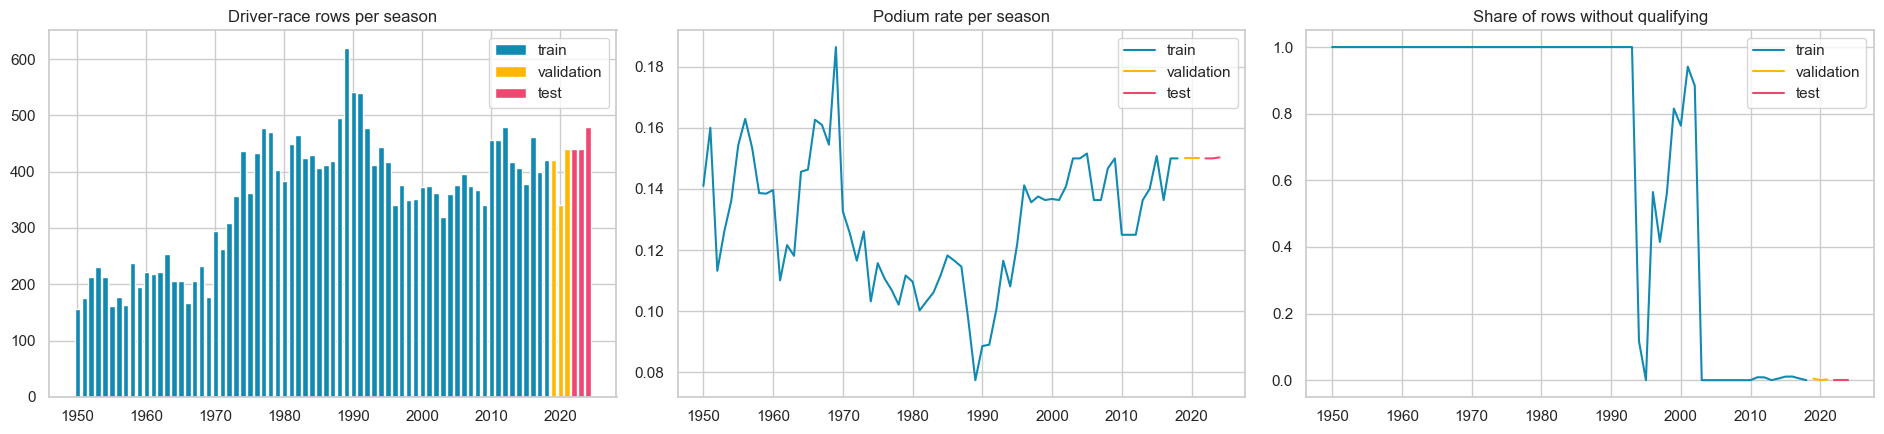

**Split.** Train <= 2018, validation 2019-2021, test 2022-2024 (the unseen ground-effect era). Whole seasons are assigned to one split, so every evaluation is a prediction of future races and no race's podium is split across partitions. Validation is used for every choice (preprocessing order, hyperparameters, thresholds, model selection); test is only scored. Preprocessing lives inside sklearn pipelines: median imputation + scaling for numeric features, an explicit `Unknown` category + one-hot encoding (unknown levels ignored) for categorical features, all fitted on training rows only. 37% of test rows are drivers never seen in training, which is why identity IDs are not predictors.

In [12]:
VALIDATION_YEARS, TEST_YEARS = (2019, 2021), (2022, 2024)
assert modeling_data["year"].max() >= TEST_YEARS[0], "Dataset must reach 2022 for the chronological test split"
split = pd.Series("train", index=modeling_data.index)
split[modeling_data["year"].between(*VALIDATION_YEARS)] = "validation"
split[modeling_data["year"] >= TEST_YEARS[0]] = "test"

X = modeling_data[feature_columns]
y = modeling_data["podium"].astype(int)
X_train, y_train = X[split == "train"], y[split == "train"]
X_val, y_val = X[split == "validation"], y[split == "validation"]
X_test, y_test = X[split == "test"], y[split == "test"]
SPLITS = {"train": (X_train, y_train), "validation": (X_val, y_val), "test": (X_test, y_test)}

years_by_split = modeling_data.groupby(split)["year"].agg(["min", "max"])
races_by_split = modeling_data.groupby(split)["raceId"].apply(set)
train_ids = {c: set(modeling_data.loc[split == "train", c]) for c in ["driverId", "constructorId"]}
split_summary = pd.DataFrame(
    {
        name: {
            "seasons": f"{int(years_by_split.loc[name, 'min'])}-{int(years_by_split.loc[name, 'max'])}",
            "rows": len(Xs),
            "races": modeling_data.loc[Xs.index, "raceId"].nunique(),
            "podium_rate": ys.mean(),
            "qualifying_missing": Xs["qualifying_missing"].mean(),
            "rows_with_driver_unseen_in_train": (~modeling_data.loc[Xs.index, "driverId"].isin(train_ids["driverId"])).mean(),
            "rows_with_constructor_unseen_in_train": (~modeling_data.loc[Xs.index, "constructorId"].isin(train_ids["constructorId"])).mean(),
        }
        for name, (Xs, ys) in SPLITS.items()
    }
).T
split_checks = pd.DataFrame(
    [
        ("every row in exactly one split", len(X_train) + len(X_val) + len(X_test) == len(X)),
        ("train ends before validation, validation before test",
         years_by_split.loc["train", "max"] < years_by_split.loc["validation", "min"] <= years_by_split.loc["validation", "max"] < years_by_split.loc["test", "min"]),
        ("no race in two splits", not (races_by_split["train"] & races_by_split["validation"] or races_by_split["validation"] & races_by_split["test"] or races_by_split["train"] & races_by_split["test"])),
        ("identical feature columns in every split", all(list(Xs.columns) == feature_columns for Xs, _ in SPLITS.values())),
        ("both classes in every split", all(ys.nunique() == 2 for _, ys in SPLITS.values())),
    ],
    columns=["check", "passes"],
)
assert split_checks["passes"].all(), split_checks
display(split_summary)
display(split_checks)


def make_preprocessor(order="impute_scale", num_cols=None, cat_cols=None):
    num_cols = numeric_features if num_cols is None else num_cols
    cat_cols = categorical_features if cat_cols is None else cat_cols
    impute, scale = ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())
    numeric = Pipeline([impute, scale] if order == "impute_scale" else [scale, impute])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)], verbose_feature_names_out=False)


def choose_threshold(y_true, proba):
    thresholds = np.linspace(0.05, 0.95, 181)
    return float(thresholds[np.argmax([f1_score(y_true, proba >= t, zero_division=0) for t in thresholds])])


def score(y_true, proba, threshold):
    pred = proba >= threshold
    return {"roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba),
            "f1": f1_score(y_true, pred, zero_division=0), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0), "threshold": threshold}


def baseline_logistic():
    return LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)


check_pre = make_preprocessor().fit(X_train)
assert np.allclose(check_pre.named_transformers_["num"].named_steps["imputer"].statistics_, X_train[numeric_features].median(), equal_nan=True)
print("Fit-on-train check passed: imputer medians equal training-split medians (validation/test only ever go through .transform).")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
per_season = modeling_data.assign(split=split).groupby(["year", "split"]).agg(rows=("podium", "size"), podium_rate=("podium", "mean"), quali_missing=("qualifying_missing", "mean")).reset_index()
for name, color in [("train", "#118ab2"), ("validation", "#ffb703"), ("test", "#ef476f")]:
    part = per_season[per_season["split"] == name]
    axes[0].bar(part["year"], part["rows"], color=color, label=name)
    axes[1].plot(part["year"], part["podium_rate"], color=color, label=name)
    axes[2].plot(part["year"], part["quali_missing"], color=color, label=name)
for ax, title in zip(axes, ["Driver-race rows per season", "Podium rate per season", "Share of rows without qualifying"]):
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()
note(
    f"**Split.** Train <= {TRAIN_END_YEAR}, validation {VALIDATION_YEARS[0]}-{VALIDATION_YEARS[1]}, test {TEST_YEARS[0]}-{TEST_YEARS[1]} (the unseen ground-effect era). "
    "Whole seasons are assigned to one split, so every evaluation is a prediction of future races and no race's podium is split across partitions. "
    "Validation is used for every choice (preprocessing order, hyperparameters, thresholds, model selection); test is only scored. "
    "Preprocessing lives inside sklearn pipelines: median imputation + scaling for numeric features, an explicit `Unknown` category + one-hot "
    "encoding (unknown levels ignored) for categorical features, all fitted on training rows only. "
    f"{split_summary.loc['test', 'rows_with_driver_unseen_in_train']:.0%} of test rows are drivers never seen in training, which is why identity IDs are not predictors."
)

=== Preprocessing experiment 1: impute -> scale vs scale -> impute (baseline logistic regression, validation only) ===


,roc_auc,pr_auc,f1,precision,recall,threshold
variant,,,,,,
impute_scale,0.9302,0.6941,0.7202,0.6748,0.7722,0.82
scale_impute,0.9302,0.6942,0.7202,0.6748,0.7722,0.82


train_missing                mean_after                  sd_after             
order                   impute_scale scale_impute impute_scale scale_impute impute_scale scale_impute
feature                                                                                              
driver_prev_points             0.146        0.146          0.0       -0.052          1.0        0.932
grid_position                  0.065        0.065         -0.0       -0.000          1.0        0.967
q3_sec                         0.901        0.901         -0.0       -0.029          1.0        0.315
qualifying_gap_to_pole         0.676        0.676          0.0       -0.041          1.0        0.570

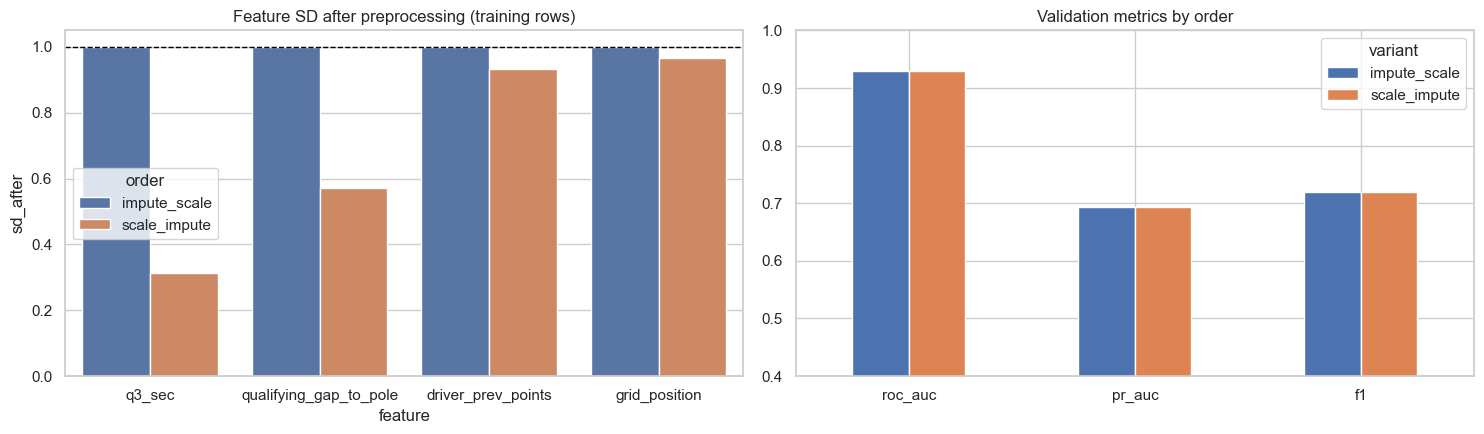

**Result.** impute -> scale minus scale -> impute = -0.0001 validation PR-AUC. Scaling first learns mean/SD from observed values only, then piles all imputed rows onto one value, so heavily-missing features (e.g. `q3_sec`) end with SD well below 1 and a non-zero mean. For a linear model a per-feature shift/rescale is mostly absorbed by the coefficient, so the metric effect is small; only the L2 penalty sees the scale difference.

In [13]:
print("=== Preprocessing experiment 1: impute -> scale vs scale -> impute (baseline logistic regression, validation only) ===")


def fit_and_score_on_validation(pipe):
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:, 1]
    return score(y_val, proba, choose_threshold(y_val, proba))


exp1_rows, exp1_distribution = [], []
for order in ["impute_scale", "scale_impute"]:
    pipe = Pipeline([("preprocess", make_preprocessor(order)), ("model", baseline_logistic())])
    exp1_rows.append({"variant": order, **fit_and_score_on_validation(pipe)})
    transformed = pd.DataFrame(pipe.named_steps["preprocess"].transform(X_train)[:, : len(numeric_features)], columns=numeric_features)
    for col in ["q3_sec", "qualifying_gap_to_pole", "driver_prev_points", "grid_position"]:
        exp1_distribution.append({"order": order, "feature": col, "train_missing": X_train[col].isna().mean(),
                                  "mean_after": transformed[col].mean(), "sd_after": transformed[col].std()})
exp1 = pd.DataFrame(exp1_rows).set_index("variant")
exp1_distribution = pd.DataFrame(exp1_distribution)
display(exp1.round(4))
display(exp1_distribution.pivot(index="feature", columns="order", values=["train_missing", "mean_after", "sd_after"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=exp1_distribution, x="feature", y="sd_after", hue="order", ax=axes[0])
axes[0].axhline(1, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Feature SD after preprocessing (training rows)")
exp1[["roc_auc", "pr_auc", "f1"]].T.plot.bar(ax=axes[1], rot=0)
axes[1].set_ylim(0.4, 1)
axes[1].set_title("Validation metrics by order")
plt.tight_layout()
plt.show()
exp1_gap = exp1.loc["impute_scale", "pr_auc"] - exp1.loc["scale_impute", "pr_auc"]
note(
    f"**Result.** impute -> scale minus scale -> impute = {exp1_gap:+.4f} validation PR-AUC. Scaling first learns mean/SD from observed values only, "
    "then piles all imputed rows onto one value, so heavily-missing features (e.g. `q3_sec`) end with SD well below 1 and a non-zero mean. "
    "For a linear model a per-feature shift/rescale is mostly absorbed by the coefficient, so the metric effect is small; only the L2 penalty sees the scale difference."
)

=== Preprocessing experiment 2: split -> fit on train (correct) vs fit on all rows -> split (leaky), validation only ===


,roc_auc,pr_auc,f1,precision,recall,threshold
split -> fit on train (correct),0.9302,0.6941,0.7202,0.6748,0.7722,0.82
fit on all rows -> split (leaky),0.9302,0.6938,0.7202,0.6748,0.7722,0.82


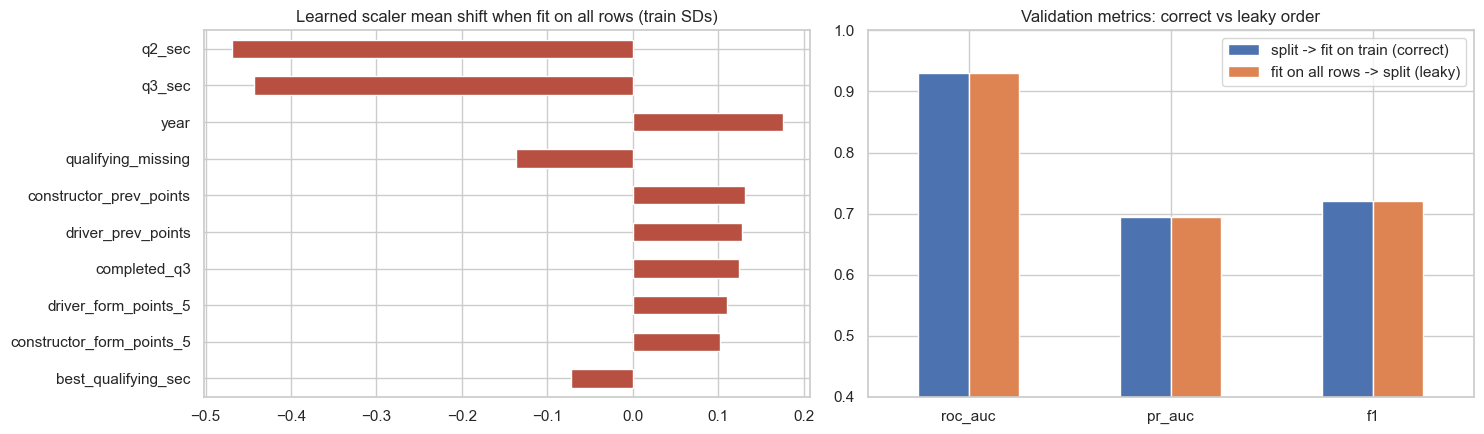

**Result.** leaky minus correct = -0.0002 validation PR-AUC. Fitting on all rows moves imputation/scaling statistics toward the modern seasons (largest shift: `q2_sec`, -0.47 train SDs) and adds 10 one-hot categories that only exist in validation/test. Whatever the metric does, the leaky score is not an honest estimate of future performance, so it is never selectable.

**Decision (validation only).** Keep impute -> scale unless scale -> impute is better by more than 0.002 PR-AUC; selected order: `impute_scale`, always fitted after the split, inside the pipeline.

In [14]:
print("=== Preprocessing experiment 2: split -> fit on train (correct) vs fit on all rows -> split (leaky), validation only ===")
leaky_pre = make_preprocessor().fit(X)
leaky_model = baseline_logistic().fit(leaky_pre.transform(X_train), y_train)
leaky_proba = leaky_model.predict_proba(leaky_pre.transform(X_val))[:, 1]
exp2 = pd.DataFrame(
    {
        "split -> fit on train (correct)": fit_and_score_on_validation(Pipeline([("preprocess", make_preprocessor()), ("model", baseline_logistic())])),
        "fit on all rows -> split (leaky)": score(y_val, leaky_proba, choose_threshold(y_val, leaky_proba)),
    }
).T
correct_scaler = check_pre.named_transformers_["num"].named_steps["scaler"]
leaky_scaler = leaky_pre.named_transformers_["num"].named_steps["scaler"]
stat_shift = pd.Series((leaky_scaler.mean_ - correct_scaler.mean_) / correct_scaler.scale_, index=numeric_features).sort_values(key=abs, ascending=False)
extra_categories = sum(map(len, leaky_pre.named_transformers_["cat"].named_steps["onehot"].categories_)) - sum(map(len, check_pre.named_transformers_["cat"].named_steps["onehot"].categories_))
display(exp2.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
stat_shift.head(10).plot.barh(ax=axes[0], color="#b85042")
axes[0].invert_yaxis()
axes[0].set_title("Learned scaler mean shift when fit on all rows (train SDs)")
exp2[["roc_auc", "pr_auc", "f1"]].T.plot.bar(ax=axes[1], rot=0)
axes[1].set_ylim(0.4, 1)
axes[1].set_title("Validation metrics: correct vs leaky order")
plt.tight_layout()
plt.show()
exp2_gap = exp2["pr_auc"].iloc[1] - exp2["pr_auc"].iloc[0]

PREPROCESSING_TOLERANCE = 0.002
PREPROCESSING_ORDER = "scale_impute" if -exp1_gap > PREPROCESSING_TOLERANCE else "impute_scale"
note(
    f"**Result.** leaky minus correct = {exp2_gap:+.4f} validation PR-AUC. Fitting on all rows moves imputation/scaling statistics toward the "
    f"modern seasons (largest shift: `{stat_shift.index[0]}`, {stat_shift.iloc[0]:+.2f} train SDs) and adds {extra_categories} one-hot categories that only "
    "exist in validation/test. Whatever the metric does, the leaky score is not an honest estimate of future performance, so it is never selectable.\n\n"
    f"**Decision (validation only).** Keep impute -> scale unless scale -> impute is better by more than {PREPROCESSING_TOLERANCE} PR-AUC; "
    f"selected order: `{PREPROCESSING_ORDER}`, always fitted after the split, inside the pipeline."
)

In [15]:
model_rows, fitted = [], {}


def build_pipeline(estimator, num_cols=None, cat_cols=None):
    return Pipeline([("preprocess", make_preprocessor(PREPROCESSING_ORDER, num_cols, cat_cols)), ("model", estimator)])


def tune_on_validation(make_estimator, grid):
    rows, best = [], (None, -np.inf, None)
    for params in ParameterGrid(grid):
        pipe = build_pipeline(make_estimator(**params)).fit(X_train, y_train)
        val_pr = average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])
        rows.append({**params, "train_pr_auc": average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1]), "validation_pr_auc": val_pr})
        if val_pr > best[1]:
            best = (pipe, val_pr, params)
    return best[0], best[2], pd.DataFrame(rows).sort_values("validation_pr_auc", ascending=False)


def register(name, pipe, family):
    assert list(pipe.feature_names_in_) == feature_columns
    proba = {s: pipe.predict_proba(Xs)[:, 1] for s, (Xs, _) in SPLITS.items()}
    threshold = choose_threshold(y_val, proba["validation"])
    fitted[name] = {"pipe": pipe, "threshold": threshold, "proba": proba, "family": family}
    for s, (_, ys) in SPLITS.items():
        model_rows.append({"model": name, "split": s, "family": family, **score(ys, proba[s], threshold)})
    display(pd.DataFrame(model_rows).query("model == @name").drop(columns="family").round(4))


print("=== Attempt 1: baseline logistic regression (C=1, balanced class weights, untuned) ===")
BASELINE = "Logistic Regression (baseline)"
register(BASELINE, build_pipeline(baseline_logistic()).fit(X_train, y_train), "statistical")
note(
    "Linear log-odds model with balanced class weights so the ~15% podium class is not ignored. It is the reference every other model must beat on validation. "
    "**Limitations:** assumes each feature shifts log-odds linearly and additively, so the sharp drop between P3 and P4 and team-by-grid interactions are only approximated."
)

=== Attempt 1: baseline logistic regression (C=1, balanced class weights, untuned) ===


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Logistic Regression (baseline),train,0.9078,0.5549,0.5503,0.5547,0.5460,0.82
1,Logistic Regression (baseline),validation,0.9302,0.6941,0.7202,0.6748,0.7722,0.82
2,Logistic Regression (baseline),test,0.9333,0.6937,0.6313,0.6209,0.6422,0.82


Linear log-odds model with balanced class weights so the ~15% podium class is not ignored. It is the reference every other model must beat on validation. **Limitations:** assumes each feature shifts log-odds linearly and additively, so the sharp drop between P3 and P4 and team-by-grid interactions are only approximated.

In [16]:
print("=== Attempt 2: random forest, tuned on validation PR-AUC ===")
RF = "Random Forest"
rf_pipe, rf_params, rf_tuning = tune_on_validation(
    lambda min_samples_leaf, max_features: RandomForestClassifier(
        n_estimators=300, min_samples_leaf=min_samples_leaf, max_features=max_features,
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    {"min_samples_leaf": [3, 10, 25], "max_features": ["sqrt", 0.3]},
)
display(rf_tuning.round(4))
register(RF, rf_pipe, "statistical")
note(
    f"Selected `{rf_params}`. Bagged deep trees capture non-linear grid effects and interactions without manual feature crosses. "
    "**Limitations:** cannot extrapolate beyond training ranges (new points scales), probabilities are poorly calibrated, and the train-validation gap shows how much it memorises."
)

=== Attempt 2: random forest, tuned on validation PR-AUC ===


,max_features,min_samples_leaf,train_pr_auc,validation_pr_auc
0,sqrt,3,0.9334,0.7517
3,0.3,3,0.9848,0.7463
4,0.3,10,0.8083,0.7455
5,0.3,25,0.6875,0.7453
1,sqrt,10,0.7232,0.7411
2,sqrt,25,0.6303,0.7326


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
3,Random Forest,train,0.9899,0.9334,0.8279,0.7337,0.9499,0.52
4,Random Forest,validation,0.9388,0.7517,0.7325,0.6878,0.7833,0.52
5,Random Forest,test,0.9352,0.6850,0.6535,0.5913,0.7304,0.52


Selected `{'max_features': 'sqrt', 'min_samples_leaf': 3}`. Bagged deep trees capture non-linear grid effects and interactions without manual feature crosses. **Limitations:** cannot extrapolate beyond training ranges (new points scales), probabilities are poorly calibrated, and the train-validation gap shows how much it memorises.

In [17]:
print("=== Attempt 3: histogram gradient boosting, tuned on validation PR-AUC ===")
HGB = "Gradient Boosting (HistGB)"
hgb_pipe, hgb_params, hgb_tuning = tune_on_validation(
    lambda learning_rate, max_leaf_nodes, l2_regularization: HistGradientBoostingClassifier(
        learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, l2_regularization=l2_regularization, max_iter=500,
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, class_weight="balanced", random_state=RANDOM_STATE),
    {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31], "l2_regularization": [0.0, 1.0]},
)
display(hgb_tuning.round(4))
register(HGB, hgb_pipe, "statistical")
note(
    f"Selected `{hgb_params}` with {hgb_pipe.named_steps['model'].n_iter_} boosting rounds; early stopping uses a 10% hold-out drawn from training rows only. "
    "**Limitations:** sensitive to learning rate / tree size, and like the forest it cannot extrapolate to unseen feature ranges."
)

=== Attempt 3: histogram gradient boosting, tuned on validation PR-AUC ===


,l2_regularization,learning_rate,max_leaf_nodes,train_pr_auc,validation_pr_auc
1,0.0,0.03,31,0.6188,0.7444
3,0.0,0.10,31,0.6546,0.7413
4,1.0,0.03,15,0.5942,0.7409
0,0.0,0.03,15,0.5991,0.7400
5,1.0,0.03,31,0.6242,0.7382
7,1.0,0.10,31,0.6404,0.7338
6,1.0,0.10,15,0.6044,0.7298
2,0.0,0.10,15,0.6070,0.7237


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
6,Gradient Boosting (HistGB),train,0.9312,0.6188,0.6048,0.5385,0.6898,0.76
7,Gradient Boosting (HistGB),validation,0.9385,0.7444,0.7286,0.6651,0.8056,0.76
8,Gradient Boosting (HistGB),test,0.9346,0.7030,0.6792,0.5934,0.7941,0.76


Selected `{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31}` with 140 boosting rounds; early stopping uses a 10% hold-out drawn from training rows only. **Limitations:** sensitive to learning rate / tree size, and like the forest it cannot extrapolate to unseen feature ranges.

pr_auc                         f1                    roc_auc                    precision                     recall                   
split                            train validation    test   train validation    test   train validation    test     train validation    test   train validation    test
model                                                                                                                                                                  
Logistic Regression (baseline)  0.5549     0.6941  0.6937  0.5503     0.7202  0.6313  0.9078     0.9302  0.9333    0.5547     0.6748  0.6209  0.5460     0.7722  0.6422
Random Forest                   0.9334     0.7517  0.6850  0.8279     0.7325  0.6535  0.9899     0.9388  0.9352    0.7337     0.6878  0.5913  0.9499     0.7833  0.7304
Gradient Boosting (HistGB)      0.6188     0.7444  0.7030  0.6048     0.7286  0.6792  0.9312     0.9385  0.9346    0.5385     0.6651  0.5934  0.6898     0.8056  0.7941

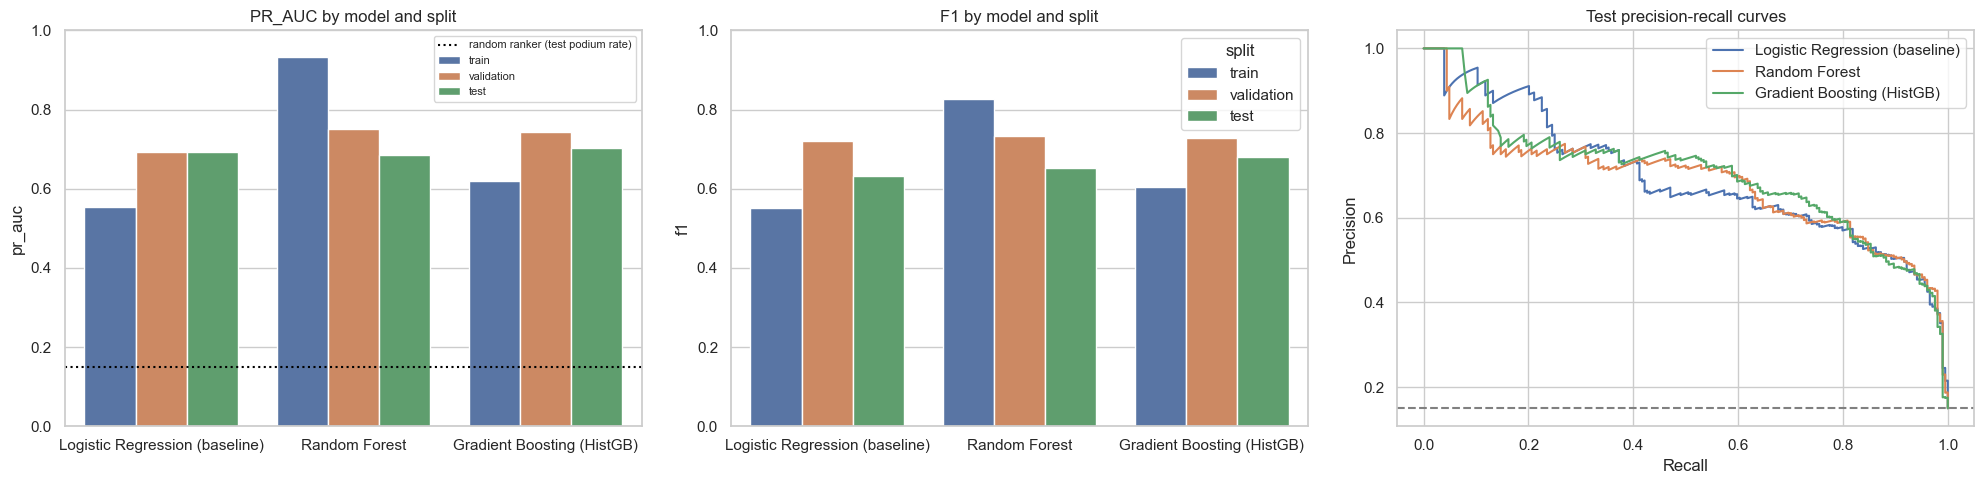

**Metric choice.** Primary: **PR-AUC**. Only ~15% of rows are podiums, and ROC-AUC is inflated by the many easy negatives (backmarkers), whereas PR-AUC measures how well the true podium finishers are ranked to the top; a random ranker scores the podium rate. Secondary: **F1 at a validation-chosen threshold**, because the companion must make a yes/no call; the threshold is frozen before test.

**Best statistical model on validation: Random Forest** (validation PR-AUC 0.7517 vs baseline 0.6941). On the unseen 2022-2024 test seasons it scores PR-AUC 0.6850 / F1 0.6535 against the baseline's 0.6937 / 0.6313. All models use identical rows, features, preprocessing, and validation-only thresholds; test scores are reported, never used for selection.

In [18]:
STATISTICAL_MODELS = [BASELINE, RF, HGB]
metrics_df = pd.DataFrame(model_rows)
stat_metrics = metrics_df[metrics_df["model"].isin(STATISTICAL_MODELS)]
display(stat_metrics.pivot(index="model", columns="split", values=["pr_auc", "f1", "roc_auc", "precision", "recall"])
        .reindex(STATISTICAL_MODELS).reindex(columns=["train", "validation", "test"], level=1).round(4))
val_pr = stat_metrics.query("split == 'validation'").set_index("model")["pr_auc"]
BEST_STATISTICAL = val_pr.idxmax()
BEST_TREE = val_pr[[RF, HGB]].idxmax()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, metric in zip(axes[:2], ["pr_auc", "f1"]):
    sns.barplot(data=stat_metrics, x="model", y=metric, hue="split", hue_order=["train", "validation", "test"], ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title(f"{metric.upper()} by model and split")
    ax.set_xlabel("")
axes[0].axhline(y_test.mean(), color="black", linestyle=":", label="random ranker (test podium rate)")
axes[0].legend(fontsize=8)
for name in STATISTICAL_MODELS:
    precision, recall, _ = precision_recall_curve(y_test, fitted[name]["proba"]["test"])
    axes[2].plot(recall, precision, label=name)
axes[2].axhline(y_test.mean(), color="gray", linestyle="--")
axes[2].set_title("Test precision-recall curves")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
plt.show()

best_row = stat_metrics.query("model == @BEST_STATISTICAL").set_index("split")
base_row = stat_metrics.query("model == @BASELINE").set_index("split")
note(
    "**Metric choice.** Primary: **PR-AUC**. Only ~15% of rows are podiums, and ROC-AUC is inflated by the many easy negatives (backmarkers), "
    "whereas PR-AUC measures how well the true podium finishers are ranked to the top; a random ranker scores the podium rate. "
    "Secondary: **F1 at a validation-chosen threshold**, because the companion must make a yes/no call; the threshold is frozen before test.\n\n"
    f"**Best statistical model on validation: {BEST_STATISTICAL}** (validation PR-AUC {best_row.loc['validation', 'pr_auc']:.4f} vs baseline "
    f"{base_row.loc['validation', 'pr_auc']:.4f}). On the unseen 2022-2024 test seasons it scores PR-AUC {best_row.loc['test', 'pr_auc']:.4f} / F1 "
    f"{best_row.loc['test', 'f1']:.4f} against the baseline's {base_row.loc['test', 'pr_auc']:.4f} / {base_row.loc['test', 'f1']:.4f}. "
    "All models use identical rows, features, preprocessing, and validation-only thresholds; test scores are reported, never used for selection."
)

,model,variant,n_features,validation_pr_auc,validation_pr_auc_delta,test_pr_auc,test_pr_auc_delta,validation_f1_delta
0,Logistic Regression (baseline),- grid,32,0.6965,0.0025,0.6820,-0.0117,-0.0119
1,Logistic Regression (baseline),- qualifying,25,0.6884,-0.0056,0.6860,-0.0077,0.0075
2,Logistic Regression (baseline),- standings,28,0.6893,-0.0047,0.7009,0.0072,0.0014
3,Logistic Regression (baseline),- form,28,0.6913,-0.0028,0.6590,-0.0347,0.0093
4,Logistic Regression (baseline),- context,23,0.7247,0.0306,0.7117,0.0180,-0.0004
5,Logistic Regression (baseline),+ driverId/constructorId (re-added),36,0.6792,-0.0149,0.6729,-0.0208,-0.0012
6,Random Forest,- grid,32,0.7377,-0.0139,0.6671,-0.0178,-0.0009
7,Random Forest,- qualifying,25,0.7206,-0.0311,0.6753,-0.0096,-0.0005
8,Random Forest,- standings,28,0.7467,-0.0050,0.6798,-0.0052,0.0005
9,Random Forest,- form,28,0.7499,-0.0018,0.6852,0.0002,0.0022


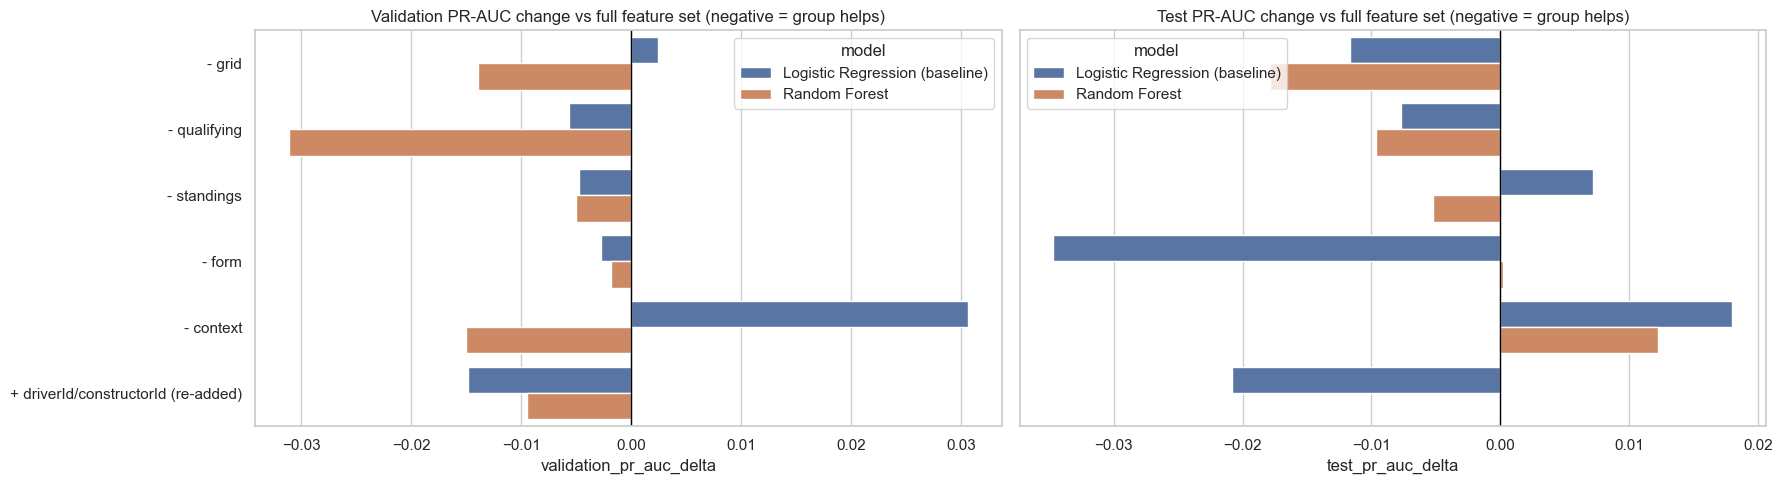

**Feature-group ablation** (each group removed, the model retrained with the same hyperparameters and a re-chosen validation threshold). **Random Forest:** removing `qualifying` costs the most validation PR-AUC (-0.0311). **Logistic Regression (baseline):** removing `qualifying` costs the most validation PR-AUC (-0.0056). Grid and qualifying overlap heavily (grid = qualifying order plus penalties), as do form and standings, so removing one member of a pair costs less than its joint contribution. **Re-adding driver/constructor IDs** changes validation / test PR-AUC by Logistic Regression (baseline): -0.0149 / -0.0208; Random Forest: -0.0095 / -0.0001, which is the evidence for keeping them out of the predictors.

In [19]:
ID_FEATURES = ["driverId", "constructorId"]
X_with_ids = pd.concat([X, modeling_data[ID_FEATURES].apply(as_category)], axis=1)
ABLATION_ESTIMATORS = {
    BASELINE: baseline_logistic,
    RF: lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE, **rf_params),
    HGB: lambda: HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
                                                class_weight="balanced", random_state=RANDOM_STATE, **hgb_params),
}
variants = [(f"- {g}", [c for c in feature_columns if c not in cols]) for g, cols in FEATURE_GROUPS.items()]
variants.append(("+ driverId/constructorId (re-added)", feature_columns + ID_FEATURES))

ablation_rows = []
for model_name in [BASELINE, BEST_TREE]:
    full = metrics_df.query("model == @model_name").set_index("split")
    for label, cols in variants:
        num_cols = [c for c in cols if c in numeric_features]
        cat_cols = [c for c in cols if c not in numeric_features]
        pipe = build_pipeline(ABLATION_ESTIMATORS[model_name](), num_cols, cat_cols).fit(X_with_ids.loc[X_train.index, cols], y_train)
        proba_val = pipe.predict_proba(X_with_ids.loc[X_val.index, cols])[:, 1]
        proba_test = pipe.predict_proba(X_with_ids.loc[X_test.index, cols])[:, 1]
        threshold = choose_threshold(y_val, proba_val)
        val_m, test_m = score(y_val, proba_val, threshold), score(y_test, proba_test, threshold)
        ablation_rows.append({
            "model": model_name, "variant": label, "n_features": len(cols),
            "validation_pr_auc": val_m["pr_auc"], "validation_pr_auc_delta": val_m["pr_auc"] - full.loc["validation", "pr_auc"],
            "test_pr_auc": test_m["pr_auc"], "test_pr_auc_delta": test_m["pr_auc"] - full.loc["test", "pr_auc"],
            "validation_f1_delta": val_m["f1"] - full.loc["validation", "f1"],
        })
ablation = pd.DataFrame(ablation_rows)
display(ablation.round(4))
ablation.to_csv(CLEANED_DIR / "feature_group_ablation.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, s in zip(axes, ["validation", "test"]):
    sns.barplot(data=ablation, y="variant", x=f"{s}_pr_auc_delta", hue="model", ax=ax)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{s.title()} PR-AUC change vs full feature set (negative = group helps)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

ablation_text = " ".join(
    f"**{m}:** removing `{part.iloc[0]['variant'][2:]}` costs the most validation PR-AUC ({part.iloc[0]['validation_pr_auc_delta']:+.4f})."
    for m, part in ablation[~ablation["variant"].str.startswith("+")].sort_values("validation_pr_auc_delta").groupby("model", sort=False)
)
ids_effect = ablation[ablation["variant"].str.startswith("+")].set_index("model")[["validation_pr_auc_delta", "test_pr_auc_delta"]]
note(
    "**Feature-group ablation** (each group removed, the model retrained with the same hyperparameters and a re-chosen validation threshold). "
    + ablation_text
    + " Grid and qualifying overlap heavily (grid = qualifying order plus penalties), as do form and standings, so removing one member of a pair "
    "costs less than its joint contribution. **Re-adding driver/constructor IDs** changes validation / test PR-AUC by "
    + "; ".join(f"{m}: {r.validation_pr_auc_delta:+.4f} / {r.test_pr_auc_delta:+.4f}" for m, r in ids_effect.iterrows())
    + ", which is the evidence for keeping them out of the predictors."
)

/private/tmp/mi-f1-refactor/venv-kaggle/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


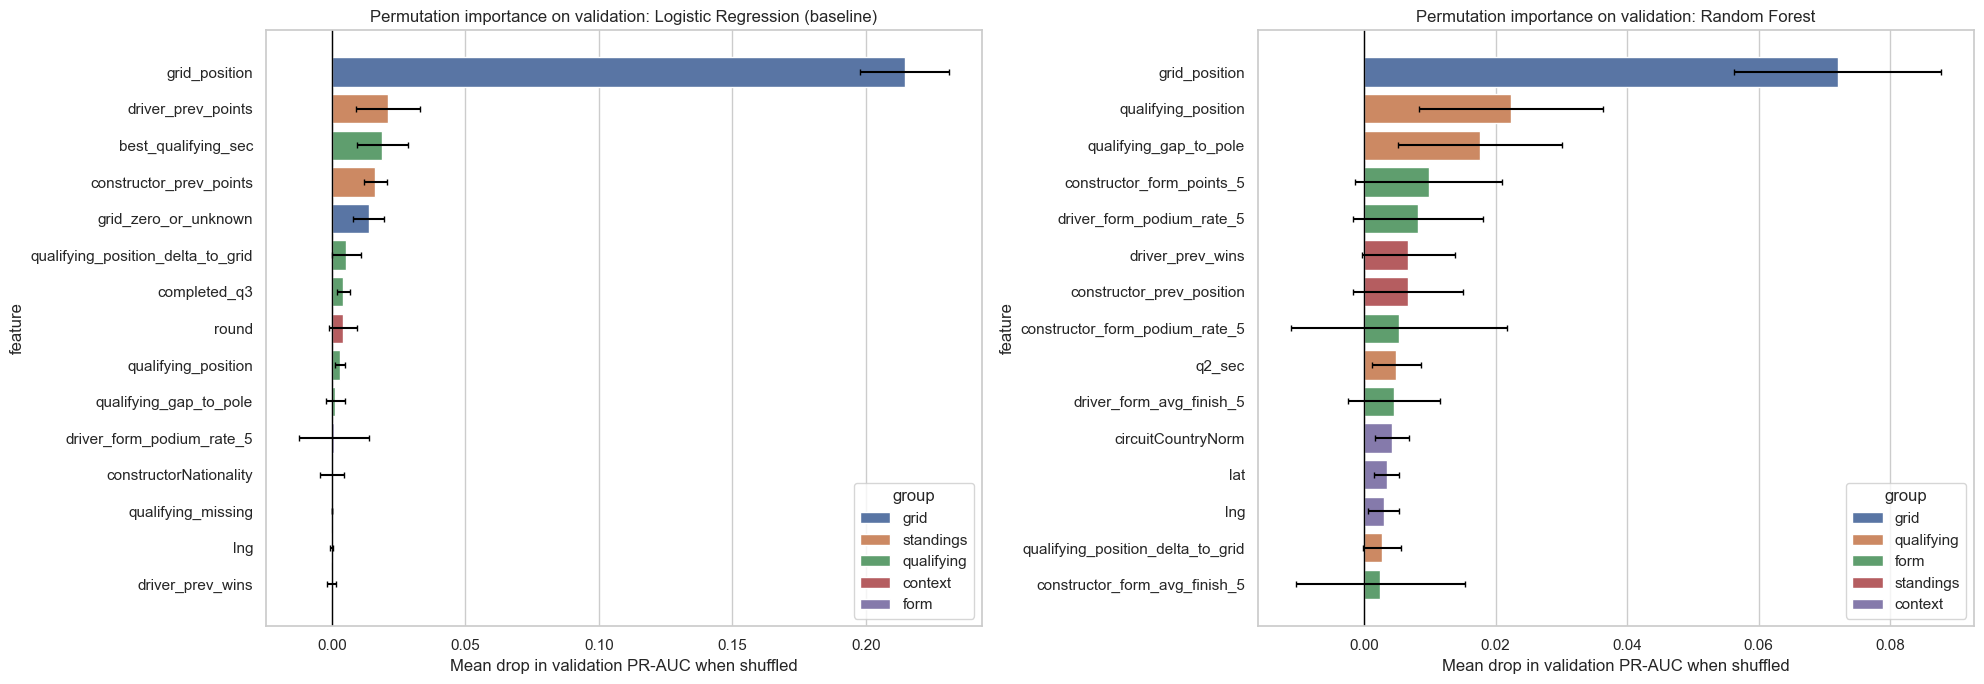

**Global permutation importance.** Each raw feature is shuffled through the full pipeline on the validation seasons. Logistic Regression (baseline) relies most on `grid_position`, `driver_prev_points`, `best_qualifying_sec`. Random Forest relies most on `grid_position`, `qualifying_position`, `qualifying_gap_to_pole`. Correlated features share credit (shuffling `grid_position` leaves `qualifying_position` intact), so individual importances understate the joint importance of starting position. This measures **model reliance, not causality**: a high constructor form value marks a car that is already fast, it does not make it faster.

In [20]:
permutation = {}
for model_name in [BASELINE, BEST_TREE]:
    result = permutation_importance(fitted[model_name]["pipe"], X_val, y_val, scoring="average_precision",
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    permutation[model_name] = pd.DataFrame(
        {"feature": feature_columns, "group": [feature_group_of[c] for c in feature_columns],
         "importance": result.importances_mean, "std": result.importances_std}
    ).sort_values("importance", ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, (model_name, table) in zip(axes, permutation.items()):
    top = table.head(15)
    sns.barplot(data=top, x="importance", y="feature", hue="group", dodge=False, ax=ax)
    ax.errorbar(top["importance"], np.arange(len(top)), xerr=top["std"], fmt="none", ecolor="black", capsize=2)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"Permutation importance on validation: {model_name}")
    ax.set_xlabel("Mean drop in validation PR-AUC when shuffled")
plt.tight_layout()
plt.show()
note(
    "**Global permutation importance.** Each raw feature is shuffled through the full pipeline on the validation seasons. "
    + " ".join(f"{m} relies most on `{'`, `'.join(t['feature'].head(3))}`." for m, t in permutation.items())
    + " Correlated features share credit (shuffling `grid_position` leaves `qualifying_position` intact), so individual importances understate "
    "the joint importance of starting position. This measures **model reliance, not causality**: a high constructor form value marks a car that is already fast, it does not make it faster."
)

# Part D — Neural network, XAI (SHAP), inference function, integrated summary

In [21]:
print("=== Attempt 4: shallow neural network (sklearn MLP), architecture tuned on validation PR-AUC ===")
NN = "Neural Network (MLP)"
nn_pipe, nn_params, nn_tuning = tune_on_validation(
    lambda hidden_layer_sizes, alpha: MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, activation="relu", batch_size=256, learning_rate_init=1e-3,
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, max_iter=300, random_state=RANDOM_STATE),
    {"hidden_layer_sizes": [(16,), (64,), (64, 32)], "alpha": [1e-4, 1e-2]},
)
display(nn_tuning.astype({"hidden_layer_sizes": str}).round(4))
register(NN, nn_pipe, "neural")

ALL_MODELS = STATISTICAL_MODELS + [NN]
metrics_df = pd.DataFrame(model_rows)
comparison = (
    metrics_df.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "f1", "precision", "recall"])
    .reindex(ALL_MODELS).reindex(columns=["train", "validation", "test"], level=1)
)
display(comparison.round(4))
comparison.to_csv(CLEANED_DIR / "model_comparison.csv")
SELECTED_MODEL = metrics_df.query("split == 'validation'").set_index("model")["pr_auc"].idxmax()
nn_row = metrics_df.query("model == @NN").set_index("split")
tree_row = metrics_df.query("model == @BEST_TREE").set_index("split")
sel_row = metrics_df.query("model == @SELECTED_MODEL").set_index("split")
note(
    f"Selected architecture `{nn_params}` (ReLU, Adam, L2 `alpha`, early stopping on a 10% hold-out of training rows), using the same rows, features, "
    "chronological split and train-fitted preprocessing as the statistical models, with a validation-chosen threshold. "
    f"Validation / test PR-AUC: NN {nn_row.loc['validation', 'pr_auc']:.4f} / {nn_row.loc['test', 'pr_auc']:.4f} vs baseline "
    f"{base_row.loc['validation', 'pr_auc']:.4f} / {base_row.loc['test', 'pr_auc']:.4f} and {BEST_TREE} "
    f"{tree_row.loc['validation', 'pr_auc']:.4f} / {tree_row.loc['test', 'pr_auc']:.4f}. "
    "**Limitations:** no class weighting in sklearn's MLP (the threshold compensates), results vary with the random seed, the early-stopping hold-out is a random "
    "(not chronological) slice of training rows, and the network is the least interpretable model.\n\n"
    f"**Selected model for XAI and inference (highest validation PR-AUC across all four attempts): {SELECTED_MODEL}** "
    f"(test PR-AUC {sel_row.loc['test', 'pr_auc']:.4f}, F1 {sel_row.loc['test', 'f1']:.4f})."
)

=== Attempt 4: shallow neural network (sklearn MLP), architecture tuned on validation PR-AUC ===


,alpha,hidden_layer_sizes,train_pr_auc,validation_pr_auc
0,0.0001,"(16,)",0.5824,0.7396
2,0.0001,"(64, 32)",0.6156,0.7388
5,0.0100,"(64, 32)",0.5871,0.7362
3,0.0100,"(16,)",0.5728,0.7267
4,0.0100,"(64,)",0.6022,0.7194
1,0.0001,"(64,)",0.6031,0.7164


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
9,Neural Network (MLP),train,0.9101,0.5824,0.5824,0.4986,0.7001,0.295
10,Neural Network (MLP),validation,0.9267,0.7396,0.7160,0.6444,0.8056,0.295
11,Neural Network (MLP),test,0.9297,0.6672,0.6429,0.5400,0.7941,0.295


roc_auc                     pr_auc                         f1                    precision                     recall                   
split                            train validation    test   train validation    test   train validation    test     train validation    test   train validation    test
model                                                                                                                                                                  
Logistic Regression (baseline)  0.9078     0.9302  0.9333  0.5549     0.6941  0.6937  0.5503     0.7202  0.6313    0.5547     0.6748  0.6209  0.5460     0.7722  0.6422
Random Forest                   0.9899     0.9388  0.9352  0.9334     0.7517  0.6850  0.8279     0.7325  0.6535    0.7337     0.6878  0.5913  0.9499     0.7833  0.7304
Gradient Boosting (HistGB)      0.9312     0.9385  0.9346  0.6188     0.7444  0.7030  0.6048     0.7286  0.6792    0.5385     0.6651  0.5934  0.6898     0.8056  0.7941
Neural Network (MLP)            0.9101     0.9267  0.9297  0.5824     0.7396  0.6672  0.5824     0.7160  0.6429    0.4986     0.6444  0.5400  0.7001     0.8056  0.7941

Selected architecture `{'alpha': 0.0001, 'hidden_layer_sizes': (16,)}` (ReLU, Adam, L2 `alpha`, early stopping on a 10% hold-out of training rows), using the same rows, features, chronological split and train-fitted preprocessing as the statistical models, with a validation-chosen threshold. Validation / test PR-AUC: NN 0.7396 / 0.6672 vs baseline 0.6941 / 0.6937 and Random Forest 0.7517 / 0.6850. **Limitations:** no class weighting in sklearn's MLP (the threshold compensates), results vary with the random seed, the early-stopping hold-out is a random (not chronological) slice of training rows, and the network is the least interpretable model.

**Selected model for XAI and inference (highest validation PR-AUC across all four attempts): Random Forest** (test PR-AUC 0.6850, F1 0.6535).

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


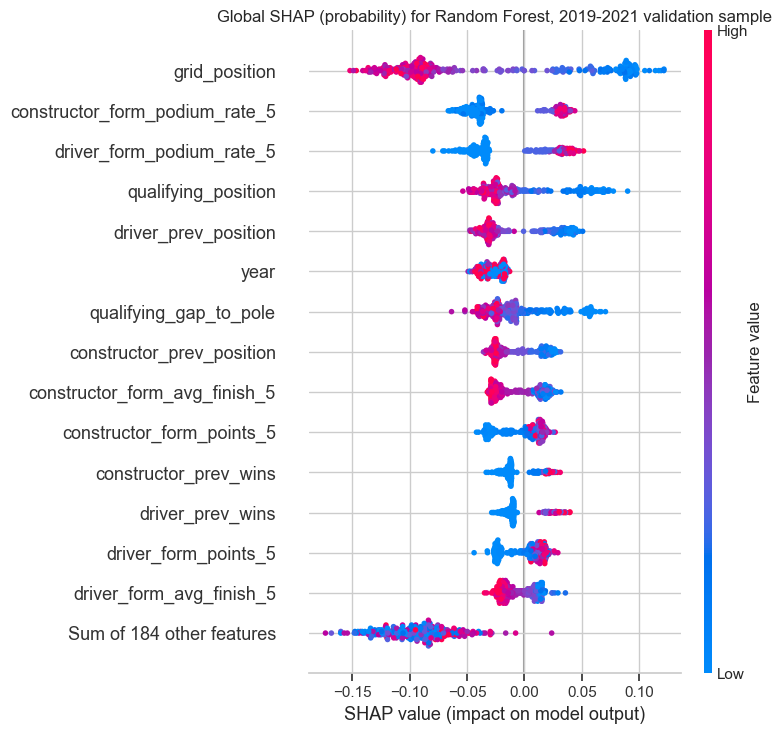

,mean_abs_shap,permutation_rank
grid_position,0.0849,1
constructor_form_podium_rate_5,0.0395,8
driver_form_podium_rate_5,0.0363,5
qualifying_position,0.0310,2
driver_prev_position,0.0308,24
year,0.0282,26
qualifying_gap_to_pole,0.0241,3
constructor_prev_position,0.0209,7
constructor_form_avg_finish_5,0.0199,15
constructor_form_points_5,0.0164,4


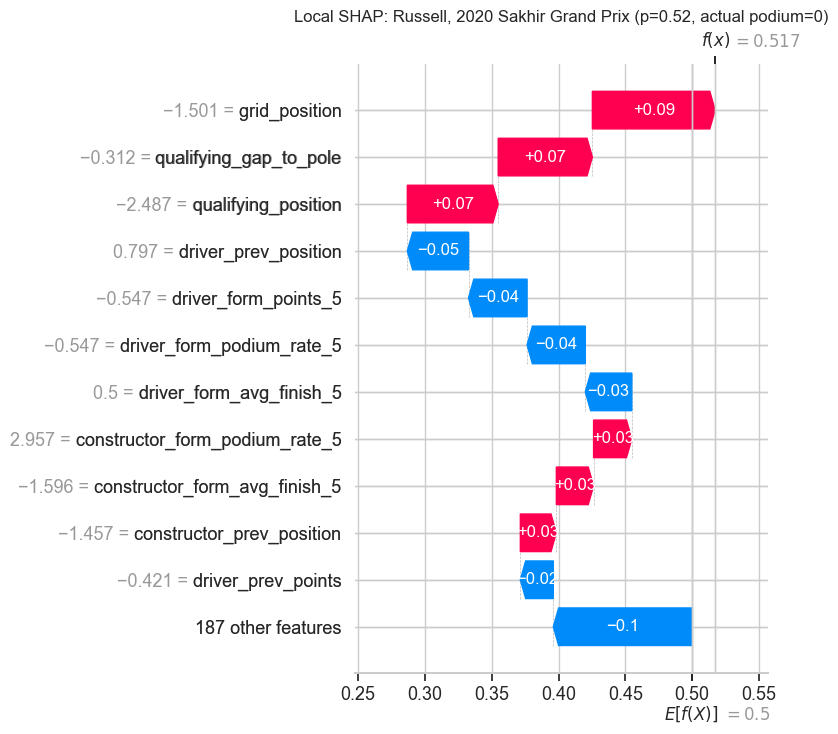

**Global SHAP (Random Forest, units: probability).** Aggregated to raw features, the model relies most on `grid_position`, `constructor_form_podium_rate_5`, `driver_form_podium_rate_5`; the beeswarm shows the direction: better (lower) grid/qualifying positions and stronger prior form push predictions toward podium. The `permutation_rank` column is the Part C permutation-importance rank for Random Forest; agreement between the two global methods means the reliance ranking is not an artefact of one explanation technique.

**Local SHAP for Russell, 2020 Sakhir Grand Prix.** This borderline case (probability 0.52 vs threshold 0.52) is driven mainly by `grid_position` (+0.092), `qualifying_gap_to_pole` (+0.071), `qualifying_position` (+0.068) relative to the model's base value.

**Not causal.** SHAP attributes this model's prediction to its inputs; it does not mean that changing a feature would change the race outcome.

In [22]:
try:
    import shap
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

selected_pipe = fitted[SELECTED_MODEL]["pipe"]
pre, estimator = selected_pipe.named_steps["preprocess"], selected_pipe.named_steps["model"]
transformed_names = list(pre.get_feature_names_out())
background = pd.DataFrame(pre.transform(X_train.sample(200, random_state=RANDOM_STATE)), columns=transformed_names)
explain_rows = X_val.sample(300 if not isinstance(estimator, MLPClassifier) else 100, random_state=RANDOM_STATE)
explain_matrix = pd.DataFrame(pre.transform(explain_rows), columns=transformed_names, index=explain_rows.index)

if isinstance(estimator, LogisticRegression):
    explainer, shap_units = shap.LinearExplainer(estimator, background), "log-odds"
elif isinstance(estimator, MLPClassifier):
    explainer = shap.Explainer(lambda a: estimator.predict_proba(a)[:, 1], shap.maskers.Independent(background, max_samples=100), algorithm="permutation")
    shap_units = "probability"
else:
    explainer = shap.TreeExplainer(estimator)
    shap_units = "probability" if isinstance(estimator, RandomForestClassifier) else "log-odds"
shap_values = explainer(explain_matrix, max_evals=2 * len(transformed_names) + 1) if isinstance(estimator, MLPClassifier) else explainer(explain_matrix)
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]


def raw_feature_of(name):
    return name if name in numeric_features else max((c for c in categorical_features if name.startswith(f"{c}_")), key=len)


permutation_reference = SELECTED_MODEL if SELECTED_MODEL in permutation else BEST_TREE
permutation_rank = {f: i + 1 for i, f in enumerate(permutation[permutation_reference]["feature"])}
shap_by_raw = (
    pd.DataFrame(np.abs(shap_values.values), columns=transformed_names).T.groupby(raw_feature_of).sum().T.mean()
    .sort_values(ascending=False).rename("mean_abs_shap").to_frame()
    .assign(permutation_rank=lambda d: d.index.map(permutation_rank))
)
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"Global SHAP ({shap_units}) for {SELECTED_MODEL}, 2019-2021 validation sample")
plt.tight_layout()
plt.show()
display(shap_by_raw.head(12).round(4))

local_proba = selected_pipe.predict_proba(explain_rows)[:, 1]
local_i = int(np.argmin(np.abs(local_proba - fitted[SELECTED_MODEL]["threshold"])))
local_key = modeling_data.loc[explain_rows.index[local_i]]
local_label = (
    f"{tables['drivers'].set_index('driverId').loc[local_key['driverId'], 'surname']}, "
    f"{int(local_key['year'])} {tables['races'].set_index('raceId').loc[local_key['raceId'], 'name']}"
)
shap.plots.waterfall(shap_values[local_i], max_display=12, show=False)
plt.title(f"Local SHAP: {local_label} (p={local_proba[local_i]:.2f}, actual podium={int(local_key['podium'])})")
plt.tight_layout()
plt.show()

top_shap = shap_by_raw.index[:3].tolist()
top_local = pd.Series(shap_values[local_i].values, index=transformed_names).sort_values(key=abs, ascending=False).head(3)
note(
    f"**Global SHAP ({SELECTED_MODEL}, units: {shap_units}).** Aggregated to raw features, the model relies most on `{'`, `'.join(top_shap)}`; "
    "the beeswarm shows the direction: better (lower) grid/qualifying positions and stronger prior form push predictions toward podium. "
    f"The `permutation_rank` column is the Part C permutation-importance rank for {permutation_reference}; agreement between the two global methods "
    "means the reliance ranking is not an artefact of one explanation technique.\n\n"
    f"**Local SHAP for {local_label}.** This borderline case (probability {local_proba[local_i]:.2f} vs threshold {fitted[SELECTED_MODEL]['threshold']:.2f}) "
    f"is driven mainly by {', '.join(f'`{k}` ({v:+.3f})' for k, v in top_local.items())} relative to the model's base value.\n\n"
    "**Not causal.** SHAP attributes this model's prediction to its inputs; it does not mean that changing a feature would change the race outcome."
)

In [23]:
FEATURE_SCHEMA = feature_dictionary[feature_dictionary["role"].str.startswith("predictor")][["column", "role", "group", "available_at"]].reset_index(drop=True)


def predict_podium(record, model_name=None):
    """Podium probability for one or more driver-race records known at the post-qualifying, pre-race cutoff.

    `record` is a dict, Series or DataFrame keyed by FEATURE_SCHEMA['column']. Missing fields are imputed by the
    trained pipeline (median / 'Unknown'); unseen categories are ignored; post-race fields are rejected.
    """
    name = model_name or SELECTED_MODEL
    frame = pd.DataFrame([record]) if isinstance(record, (dict, pd.Series)) else pd.DataFrame(record).copy()
    leaked = FORBIDDEN_COLUMNS.intersection(frame.columns) - {"driverId", "constructorId"}
    if leaked:
        raise ValueError(f"Post-race fields are not allowed at the pre-race cutoff: {sorted(leaked)}")
    missing_inputs = frame.reindex(columns=feature_columns).isna().sum(axis=1)
    frame = frame.reindex(columns=feature_columns)
    frame[numeric_features] = frame[numeric_features].apply(pd.to_numeric, errors="coerce")
    for col in categorical_features:
        frame[col] = as_category(frame[col])
    proba = fitted[name]["pipe"].predict_proba(frame)[:, 1]
    threshold = fitted[name]["threshold"]
    return pd.DataFrame({"model": name, "podium_probability": proba.round(4), "threshold": threshold,
                         "podium_prediction": proba >= threshold, "missing_inputs_imputed": missing_inputs.to_numpy()})


display(FEATURE_SCHEMA)
demo_index = modeling_data.index[(split == "test") & (modeling_data["grid_position"] <= 3) & (modeling_data["qualifying_missing"] == 0)][0]
complete_record = X.loc[demo_index].to_dict()
partial_record = {k: complete_record[k] for k in ["year", "round", "circuitId", "grid_position", "driver_form_podium_rate_5"]}
demo = pd.concat(
    [predict_podium(complete_record).assign(record="complete (all fields)"),
     predict_podium(partial_record).assign(record="partial (5 fields)"),
     predict_podium({}).assign(record="empty (all imputed)")],
    ignore_index=True,
)
display(demo)
assert demo["podium_probability"].between(0, 1).all()
assert np.isclose(demo.loc[0, "podium_probability"], fitted[SELECTED_MODEL]["pipe"].predict_proba(X.loc[[demo_index]])[:, 1][0], atol=1e-4)
try:
    predict_podium({**complete_record, "positionOrder": 1})
except ValueError as err:
    print(f"Leakage guard works: {err}")
print(f"Demo row: {modeling_data.loc[demo_index, ['raceId', 'driverId', 'year']].to_dict()}, actual podium = {int(y.loc[demo_index])}")

,column,role,group,available_at
0,grid_position,predictor (numeric),grid,"post-qualifying, pre-race"
1,grid_zero_or_unknown,predictor (numeric),grid,"post-qualifying, pre-race"
2,qualifying_position,predictor (numeric),qualifying,"post-qualifying, pre-race"
3,q1_sec,predictor (numeric),qualifying,"post-qualifying, pre-race"
4,q2_sec,predictor (numeric),qualifying,"post-qualifying, pre-race"
5,q3_sec,predictor (numeric),qualifying,"post-qualifying, pre-race"
6,best_qualifying_sec,predictor (numeric),qualifying,"post-qualifying, pre-race"
7,completed_q3,predictor (numeric),qualifying,"post-qualifying, pre-race"
8,qualifying_missing,predictor (numeric),qualifying,"post-qualifying, pre-race"
9,qualifying_gap_to_pole,predictor (numeric),qualifying,"post-qualifying, pre-race"


,model,podium_probability,threshold,podium_prediction,missing_inputs_imputed,record
0,Random Forest,0.7858,0.52,True,6,complete (all fields)
1,Random Forest,0.3657,0.52,False,29,partial (5 fields)
2,Random Forest,0.0038,0.52,False,34,empty (all imputed)


Leakage guard works: Post-race fields are not allowed at the pre-race cutoff: ['positionOrder']
Demo row: {'raceId': 1074, 'driverId': 830, 'year': 2022}, actual podium = 0


In [24]:
summary = f"""
## Integrated results summary

**Data audit.** {len(TABLES)} tables cleaned on copies; {int(cleaning_log['sentinel_or_blank_to_missing'].sum()):,} sentinel cells became missing; all primary keys unique and non-null; {int(fk_audit['orphan_rows'].sum())} foreign-key orphan rows. Driver-race grain: {grain_audit['rows_removed'].iloc[0]} shared-drive rows removed, {len(results_one):,} unique `(raceId, driverId)` rows, podium = `positionOrder <= 3`.

**DE Q1 (front row to podium, pre/post 2014).** {q1_answer}

**DE Q2 (home race, grid-controlled).** {q2_answer}

**DE Q3 (mechanical retirements).** {q3_answer}.

**Modeling.** {len(modeling_data):,} rows x {len(feature_columns)} pre-race features (grid, qualifying, prior standings, prior form, context; driver/constructor IDs excluded). Train <= {TRAIN_END_YEAR}, validation {VALIDATION_YEARS[0]}-{VALIDATION_YEARS[1]}, test {TEST_YEARS[0]}-{TEST_YEARS[1]}. Preprocessing order `{PREPROCESSING_ORDER}`, fit on train only (experiment gaps: order {exp1_gap:+.4f}, leaky fit {exp2_gap:+.4f} validation PR-AUC).

**Models (validation / test PR-AUC).** {'; '.join(f"{m}: {comparison.loc[m, ('pr_auc', 'validation')]:.3f} / {comparison.loc[m, ('pr_auc', 'test')]:.3f}" for m in ALL_MODELS)}. Selected: **{SELECTED_MODEL}** (test F1 {sel_row.loc['test', 'f1']:.3f}, precision {sel_row.loc['test', 'precision']:.3f}, recall {sel_row.loc['test', 'recall']:.3f}).

**Era sensitivity.** Qualifying is missing for {split_summary.loc['train', 'qualifying_missing']:.0%} of training rows vs {split_summary.loc['test', 'qualifying_missing']:.0%} of test rows; {split_summary.loc['test', 'rows_with_driver_unseen_in_train']:.0%} of test rows are drivers unseen in training; podium prevalence rises from {split_summary.loc['train', 'podium_rate']:.1%} (train) to {split_summary.loc['test', 'podium_rate']:.1%} (test) as fields shrink.

**Explanations are not causal.** Permutation importance and SHAP describe what the model relies on, not what causes podiums.
"""
note(summary)
(CLEANED_DIR / "results_summary.md").write_text(summary, encoding="utf-8")


## Integrated results summary

**Data audit.** 14 tables cleaned on copies; 160,144 sentinel cells became missing; all primary keys unique and non-null; 0 foreign-key orphan rows. Driver-race grain: 91 shared-drive rows removed, 26,668 unique `(raceId, driverId)` rows, podium = `positionOrder <= 3`.

**DE Q1 (front row to podium, pre/post 2014).** Across 21 circuits with at least 6 front-row starts in both eras, the highest 2014+ conversion is at Suzuka Circuit (89%), Circuit Park Zandvoort (88%), Yas Marina Circuit (86%); before 2014 the leaders were Suzuka Circuit (70%), Sepang International Circuit (70%), Hungaroring (68%). Overall front-row conversion moved from 56.0% to 76.0%. The circuit ranking is only weakly preserved (Spearman rank correlation 0.06); the largest shifts are Circuit de Monaco (+36%), Circuit Park Zandvoort (+29%), Circuit de Spa-Francorchamps (+27%).

**DE Q2 (home race, grid-controlled).** Crude podium rates are 0.115 at home vs 0.138 elsewhere, but home starts are not distributed like other starts across the grid. Standardised to the same grid-band mix, the home podium rate is 0.133 vs 0.136 elsewhere (-0.003); the Mantel-Haenszel grid-stratified odds ratio is 0.97.

**DE Q3 (mechanical retirements).** 2014-2021: Caterham 23.5% (8/34), Lotus F1 18.7% (14/75), Toro Rosso 16.1% (39/242); 2022-2024: Alfa Romeo 12.5% (11/88), Alpine F1 Team 11.0% (15/136), AlphaTauri 8.0% (7/88).

**Modeling.** 26,668 rows x 34 pre-race features (grid, qualifying, prior standings, prior form, context; driver/constructor IDs excluded). Train <= 2018, validation 2019-2021, test 2022-2024. Preprocessing order `impute_scale`, fit on train only (experiment gaps: order -0.0001, leaky fit -0.0002 validation PR-AUC).

**Models (validation / test PR-AUC).** Logistic Regression (baseline): 0.694 / 0.694; Random Forest: 0.752 / 0.685; Gradient Boosting (HistGB): 0.744 / 0.703; Neural Network (MLP): 0.740 / 0.667. Selected: **Random Forest** (test F1 0.654, precision 0.591, recall 0.730).

**Era sensitivity.** Qualifying is missing for 67% of training rows vs 0% of test rows; 37% of test rows are drivers unseen in training; podium prevalence rises from 12.5% (train) to 15.0% (test) as fields shrink.

**Explanations are not causal.** Permutation importance and SHAP describe what the model relies on, not what causes podiums.


2359